# **Transcriptomic profiling and impacted metabolic pathways in  Metabolic dysfunction-associated steatotic liver disease Non-alcoholic fatty liver disease (NAFLD)** jupyter notebook

Mounting to google drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Installing pydeseq2, a native Python re-implementation of DESeq2 for differential expression analysis (DEA) in bulk RNA-sequencing data in order to to model raw gene read counts and statistically identify which genes change significantly across different biological conditions.

In [ ]:
!pip install pydeseq2

Confirming the version of pandas and pydeseq intalled on google colab

In [ ]:
import pydeseq2
import pandas as pd

print("PyDESeq2 version:", pydeseq2.__version__)
print("Pandas version:", pd.__version__)

PyDESeq2 version: 0.5.4
Pandas version: 3.0.5


# The order of the pipeline followed in this analysis:

GEO GSE260666
       ↓
Download counts file
       ↓
Upload to Google Drive
       ↓
Open Google Colab
       ↓
Mount Google Drive
       ↓
Load count matrix
       ↓
Check samples + metadata
       ↓
QC/filtering
       ↓
Normalization
       ↓
Differential expression
       ↓
Volcano plot
       ↓
Heatmap
       ↓
GO enrichment
       ↓
KEGG/pathway analysis
       ↓
Biological interpretation

Confriming my dataset from *GSE260666* supplementary file was downloaded in my google drive folder location

In [ ]:
import os

data_path = "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/data"

os.listdir(data_path)

['GSE260666_raw_counts.txt.gz',
 'normalized_counts_pydeseq2.csv',
 'size_factors_pydeseq2.csv',
 'DE_results_NAFLD_vs_Control.csv',
 'significant_DEGs_NAFLD_vs_Control.csv']

Importing pandas and visualizing the dataset structure downlaod from the GEO accession downloaded into my drive.
The output shows that the symbols here represent the gene IDs, as the second column while the donor ID (row) accounts for the various genes expressed across the 16 samples.

*Rows = genes
Columns = biological samples
Numbers = expression/counts for that gene in that particular sample*

In [ ]:
import pandas as pd

counts_path = "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/data/GSE260666_raw_counts.txt.gz"

counts = pd.read_csv(
    counts_path,
    sep="\t",
    compression="gzip"
)

counts.head()

,Symbol,21120D1,21124D1,22068D1,22085D1,22113D1,22114D1,21149D1,21151D1,22054D1,22092D1,22093D1,22095D1,22105D1,22120D1,22123D1,22130D1
0,MT-CO1,4134684,2819239,2463072,2403950,524680,887429,3277681,1191277,2233341,2874975,1579136,1907216,708640,596105,1101671,708067
1,FGA,581969,605758,862571,1004633,792576,1343162,803376,757195,618405,1292532,1827871,2062403,1767319,1001707,1245505,1264805
2,FGB,769231,974998,955979,1382351,764381,1061647,1083602,682798,451580,1645611,1963597,1697046,1239898,849407,1053191,773021
3,HP,399327,754112,1201438,1291929,831804,1402184,1107683,1175302,479363,1372654,1096472,1261660,896933,761310,1754098,958607
4,MT-ND4,2004134,1219281,933026,1122588,511760,454633,1390429,880844,1031762,1223998,787384,789771,375951,279749,589205,342420


This shows that our data table has 37823 rows representing the genes and 17 columns representing the 16 samples plus the numbers (index) column.

In [ ]:
counts.shape

(37823, 17)

To visualize all the available columns

In [ ]:
counts.columns.tolist()

['Symbol',
 '21120D1',
 '21124D1',
 '22068D1',
 '22085D1',
 '22113D1',
 '22114D1',
 '21149D1',
 '21151D1',
 '22054D1',
 '22092D1',
 '22093D1',
 '22095D1',
 '22105D1',
 '22120D1',
 '22123D1',
 '22130D1']

This was done to get details about the counts dataset downloaded, it reveals the range of the rows, the total columns, checks for the presence of null(empty) gene cells across the columns and also confirms the datatye, which as expected should be integers except for the header rows which is the donor ID and symbol and is a string. In addition, it shared the memory usage.

In [ ]:
counts.info()

<class 'pandas.DataFrame'>
RangeIndex: 37823 entries, 0 to 37822
Data columns (total 17 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   Symbol   37823 non-null  str  
 1   21120D1  37823 non-null  int64
 2   21124D1  37823 non-null  int64
 3   22068D1  37823 non-null  int64
 4   22085D1  37823 non-null  int64
 5   22113D1  37823 non-null  int64
 6   22114D1  37823 non-null  int64
 7   21149D1  37823 non-null  int64
 8   21151D1  37823 non-null  int64
 9   22054D1  37823 non-null  int64
 10  22092D1  37823 non-null  int64
 11  22093D1  37823 non-null  int64
 12  22095D1  37823 non-null  int64
 13  22105D1  37823 non-null  int64
 14  22120D1  37823 non-null  int64
 15  22123D1  37823 non-null  int64
 16  22130D1  37823 non-null  int64
dtypes: int64(16), str(1)
memory usage: 5.2 MB


A brief look at the GSE260666 file on the GEO accession paper reveals which samples are controls, NAFL and NASH. Using that information to create a metadata table with sample and disease-group for future analysis.

Creating the metadata table

In [ ]:
metadata = pd.DataFrame({
    "Sample": [
        "21120D1", "21124D1", "22068D1", "22085D1",
        "22113D1", "22114D1",
        "21149D1", "21151D1", "22105D1", "22120D1",
        "22123D1", "22130D1",
        "22054D1", "22092D1", "22093D1", "22095D1"
    ],

    "Group": [
        "Control", "Control", "Control", "Control",
        "Control", "Control",
        "NAFL", "NAFL", "NAFL", "NAFL",
        "NAFL", "NAFL",
        "NASH", "NASH", "NASH", "NASH"
    ]
})

metadata

,Sample,Group
0,21120D1,Control
1,21124D1,Control
2,22068D1,Control
3,22085D1,Control
4,22113D1,Control
5,22114D1,Control
6,21149D1,NAFL
7,21151D1,NAFL
8,22105D1,NAFL
9,22120D1,NAFL


Confirming the disease group(Group) assigned to each sample matches the count on the GEO paper.

In [ ]:
metadata["Group"].value_counts()

Group
Control    6
NAFL       6
NASH       4
Name: count, dtype: int64

The research requires only two types of sample, a control i.e., healthy sample and diseased sample which could either be, NAFL or NASH, all categorized as NAFLD. This is done by creating a new column called Analysis group.

In [ ]:
metadata["Analysis_Group"] = metadata["Group"].replace({
    "NAFL": "NAFLD",
    "NASH": "NAFLD"
})

metadata

,Sample,Group,Analysis_Group
0,21120D1,Control,Control
1,21124D1,Control,Control
2,22068D1,Control,Control
3,22085D1,Control,Control
4,22113D1,Control,Control
5,22114D1,Control,Control
6,21149D1,NAFL,NAFLD
7,21151D1,NAFL,NAFLD
8,22105D1,NAFL,NAFLD
9,22120D1,NAFL,NAFLD


Cross-checking to ensure the samples in our organically created metadata with information from the GEO website matches the sample IDs from the downloaded supplementary file containing our counts matrix and initial dataset.

In [ ]:
count_samples = counts.columns[1:].tolist()

print("Count matrix samples:")
print(count_samples)

print("\nMetadata samples:")
print(metadata["Sample"].tolist())

print("\nAll samples match:",
      set(count_samples) == set(metadata["Sample"]))

Count matrix samples:
['21120D1', '21124D1', '22068D1', '22085D1', '22113D1', '22114D1', '21149D1', '21151D1', '22054D1', '22092D1', '22093D1', '22095D1', '22105D1', '22120D1', '22123D1', '22130D1']

Metadata samples:
['21120D1', '21124D1', '22068D1', '22085D1', '22113D1', '22114D1', '21149D1', '21151D1', '22105D1', '22120D1', '22123D1', '22130D1', '22054D1', '22092D1', '22093D1', '22095D1']

All samples match: True


Making "Symbol" the gene identifier, this removes the numbered column and makes the symbol column(gene IDs) as the first column

In [ ]:
counts = counts.set_index("Symbol")

counts.head()

,21120D1,21124D1,22068D1,22085D1,22113D1,22114D1,21149D1,21151D1,22054D1,22092D1,22093D1,22095D1,22105D1,22120D1,22123D1,22130D1
Symbol,,,,,,,,,,,,,,,,
MT-CO1,4134684,2819239,2463072,2403950,524680,887429,3277681,1191277,2233341,2874975,1579136,1907216,708640,596105,1101671,708067
FGA,581969,605758,862571,1004633,792576,1343162,803376,757195,618405,1292532,1827871,2062403,1767319,1001707,1245505,1264805
FGB,769231,974998,955979,1382351,764381,1061647,1083602,682798,451580,1645611,1963597,1697046,1239898,849407,1053191,773021
HP,399327,754112,1201438,1291929,831804,1402184,1107683,1175302,479363,1372654,1096472,1261660,896933,761310,1754098,958607
MT-ND4,2004134,1219281,933026,1122588,511760,454633,1390429,880844,1031762,1223998,787384,789771,375951,279749,589205,342420


Make the metadata index match the count matrix by making the sample column the index as well.

In [ ]:
metadata = metadata.set_index("Sample")

metadata

,Group,Analysis_Group
Sample,,
21120D1,Control,Control
21124D1,Control,Control
22068D1,Control,Control
22085D1,Control,Control
22113D1,Control,Control
22114D1,Control,Control
21149D1,NAFL,NAFLD
21151D1,NAFL,NAFLD
22105D1,NAFL,NAFLD


Confirming both the metadata index(Sample) from the GEO and the dataset downloaded columns(Sample) match

In [ ]:
metadata = metadata.loc[counts.columns]

print("Samples aligned:", all(metadata.index == counts.columns))

Samples aligned: True


# QC of Raw Counts

Performing quality control on the downloaded raw counts requires us answering these questions:

1. Does every sample have a reasonable library size? (Total no. of counts in each sample)

2. Are any samples obvious outliers?

3. Does the expression distribution look broadly comparable across samples before normalization?

Calculating the library sizes per sample (First row of counts), i.e., total number of counts in each sample.

In [ ]:
library_sizes = counts.sum(axis=0)

library_sizes

21120D1    39930273
21124D1    32305525
22068D1    37282991
22085D1    36444811
22113D1    30292826
22114D1    29762532
21149D1    37390286
21151D1    33889929
22054D1    38474058
22092D1    50295668
22093D1    44732460
22095D1    43764427
22105D1    29016203
22120D1    25208109
22123D1    32125176
22130D1    28104014
dtype: int64

Re-arranging the library size in ascending order

In [ ]:
library_sizes.sort_values(ascending=False)

22092D1    50295668
22093D1    44732460
22095D1    43764427
21120D1    39930273
22054D1    38474058
21149D1    37390286
22068D1    37282991
22085D1    36444811
21151D1    33889929
21124D1    32305525
22123D1    32125176
22113D1    30292826
22114D1    29762532
22105D1    29016203
22130D1    28104014
22120D1    25208109
dtype: int64

Importing matplotlib and numpy libraries

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

Plotting the library size per sample using a bar chart

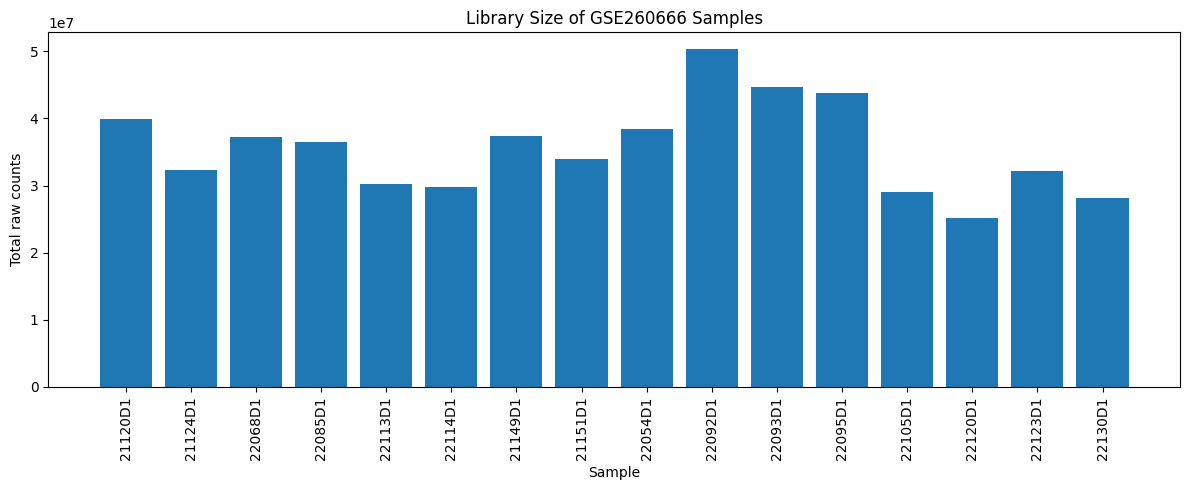

In [ ]:
plt.figure(figsize=(12, 5))

plt.bar(library_sizes.index, library_sizes.values)

plt.xticks(rotation=90)
plt.ylabel("Total raw counts")
plt.xlabel("Sample")
plt.title("Library Size of GSE260666 Samples")

plt.tight_layout()
plt.show()

Adding a new column called Total counts to show the library size of each sample.

In [ ]:
library_qc = pd.DataFrame({
    "Total_Counts": library_sizes
})

library_qc = library_qc.join(metadata)

library_qc

,Total_Counts,Group,Analysis_Group
21120D1,39930273,Control,Control
21124D1,32305525,Control,Control
22068D1,37282991,Control,Control
22085D1,36444811,Control,Control
22113D1,30292826,Control,Control
22114D1,29762532,Control,Control
21149D1,37390286,NAFL,NAFLD
21151D1,33889929,NAFL,NAFLD
22054D1,38474058,NASH,NAFLD
22092D1,50295668,NASH,NAFLD


Log-transformed distribution

Plotting a box plot for the log count of each sample and to check if the overall count distributions wildly differ between samples. The results reveal that there is no obvious sample with a dramatically abnormal distribution.

/tmp/ipykernel_11991/1240165592.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


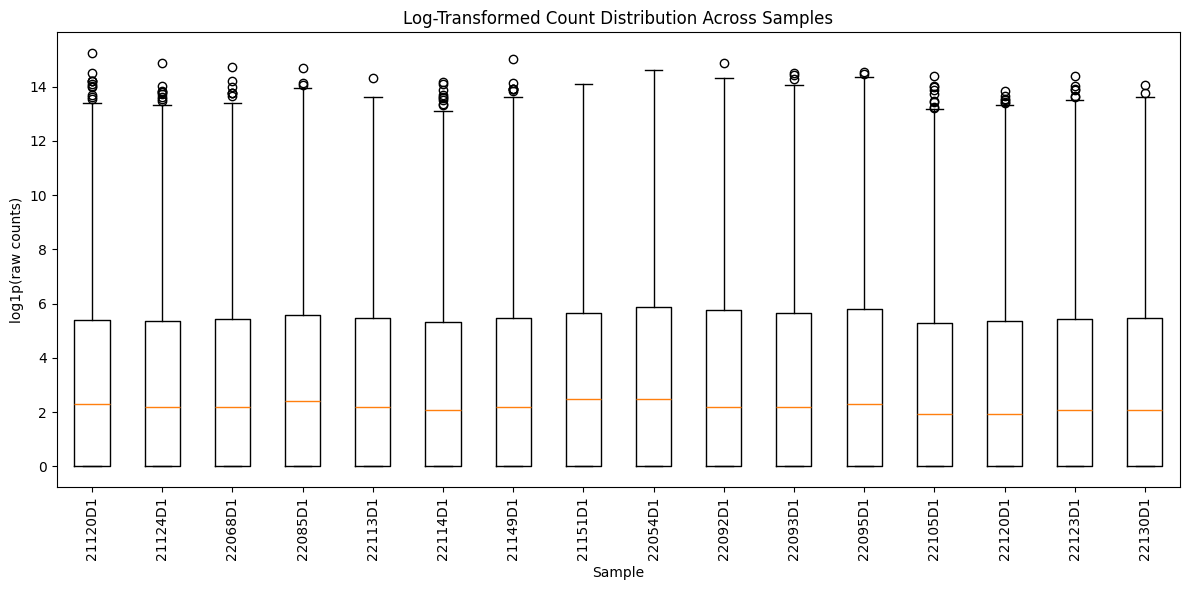

In [ ]:

log_counts = np.log1p(counts)

plt.figure(figsize=(12, 6))

plt.boxplot(
    [log_counts[sample] for sample in log_counts.columns],
    labels=log_counts.columns
)

plt.xticks(rotation=90)
plt.ylabel("log1p(raw counts)")
plt.xlabel("Sample")
plt.title("Log-Transformed Count Distribution Across Samples")

plt.tight_layout()
plt.show()

Sample correlation

This correlation shows the relationship between samples, answering the question, Are samples broadly expressing genes in a similar overall pattern?
The results gotten here are 0.92–0.96, which is very high.
No obvious sample behaved completely differently from the others.

In [ ]:
correlation = log_counts.corr()

correlation.round(2)

,21120D1,21124D1,22068D1,22085D1,22113D1,22114D1,21149D1,21151D1,22054D1,22092D1,22093D1,22095D1,22105D1,22120D1,22123D1,22130D1
21120D1,1.00,0.95,0.94,0.93,0.93,0.93,0.94,0.92,0.93,0.92,0.93,0.93,0.93,0.93,0.94,0.93
21124D1,0.95,1.00,0.95,0.94,0.94,0.94,0.95,0.94,0.94,0.94,0.94,0.95,0.94,0.95,0.95,0.95
22068D1,0.94,0.95,1.00,0.95,0.94,0.95,0.95,0.94,0.94,0.93,0.95,0.95,0.94,0.95,0.95,0.94
22085D1,0.93,0.94,0.95,1.00,0.95,0.95,0.94,0.95,0.93,0.94,0.95,0.95,0.93,0.95,0.95,0.94
22113D1,0.93,0.94,0.94,0.95,1.00,0.95,0.94,0.95,0.93,0.93,0.95,0.94,0.92,0.94,0.96,0.94
22114D1,0.93,0.94,0.95,0.95,0.95,1.00,0.94,0.95,0.94,0.94,0.96,0.95,0.94,0.96,0.96,0.95
21149D1,0.94,0.95,0.95,0.94,0.94,0.94,1.00,0.93,0.94,0.94,0.95,0.95,0.94,0.95,0.95,0.94
21151D1,0.92,0.94,0.94,0.95,0.95,0.95,0.93,1.00,0.93,0.93,0.95,0.95,0.92,0.94,0.95,0.94
22054D1,0.93,0.94,0.94,0.93,0.93,0.94,0.94,0.93,1.00,0.94,0.93,0.94,0.94,0.95,0.94,0.94
22092D1,0.92,0.94,0.93,0.94,0.93,0.94,0.94,0.93,0.94,1.00,0.94,0.95,0.94,0.95,0.94,0.95


A heatmap was plotted for the sample correlation

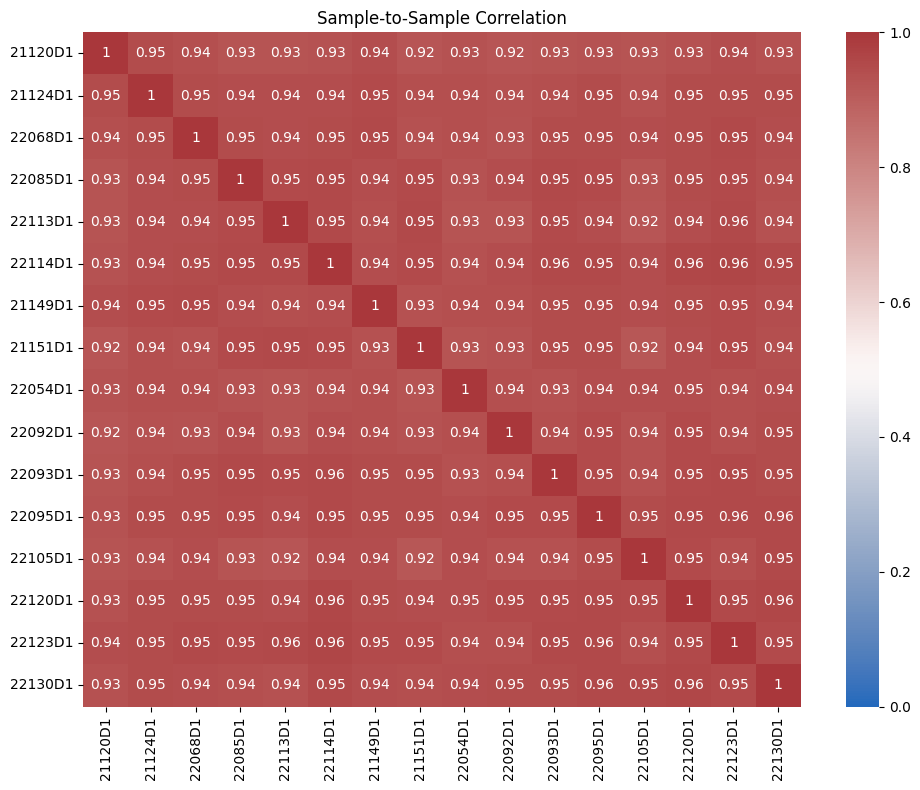

In [ ]:
import seaborn as sns

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    cmap="vlag",
    vmin=0,
    vmax=1,
    annot=True
)

plt.title("Sample-to-Sample Correlation")

plt.tight_layout()
plt.show()

Gene filtering

This was done to ensure only viable genes are analyzed. So genes with at least 10 counts in at least 3 samples were kept.

In [ ]:
min_counts = 10
min_samples = 3

keep_genes = (counts >= min_counts).sum(axis=1) >= min_samples

print("Genes before filtering:", counts.shape[0])
print("Genes after filtering:", keep_genes.sum())
print("Genes removed:", (~keep_genes).sum())

Genes before filtering: 37823
Genes after filtering: 21141
Genes removed: 16682


Printing the shape of the genes filtered previously

In [ ]:
counts_filtered = counts.loc[keep_genes].copy()

print("Filtered count matrix shape:", counts_filtered.shape)

Filtered count matrix shape: (21141, 16)


In [ ]:
print("Minimum number of samples with >=10 counts:",
      (counts_filtered >= 10).sum(axis=1).min())

Minimum number of samples with >=10 counts: 3


Normalization

Using the count-aware normalization method

Using the DESeq2 median-of-ratios normalization, implemented in Python through PyDESeq2 via sample-specific size factors to account for differences in sequencing depth and RNA composition.

In [ ]:
from pydeseq2.preprocessing import deseq2_norm

Transposing the filtered genes counts matrix so that the samples become rows and genes columns.

In [ ]:
counts_for_norm = counts_filtered.T

print("Shape for normalization:", counts_for_norm.shape)

Shape for normalization: (16, 21141)


Using the Deseq2 to normalize the filtered genes

In [ ]:
normalized_counts, size_factors = deseq2_norm(counts_for_norm)

Inspecting the size factors results after Deseq2 of the 16 samples

In [ ]:
print(size_factors)

[0.93536613 0.87464224 0.96234514 1.04815499 0.9140265  0.84208608
 1.00185652 1.10589132 1.47443376 1.30671331 1.23406321 1.31081918
 0.85043025 0.83718773 0.90743336 0.92379629]


In [ ]:
print("Size factor range:",
      size_factors.min(),
      "to",
      size_factors.max())

Size factor range: 0.8371877282241561 to 1.4744337639220673


Checking the normalized count matrix of the samples after Deseq2

Normalized counts are mainly useful for:

• visualization
• PCA
• heatmaps
• exploratory expression plots

In [ ]:
print("Normalized counts shape:", normalized_counts.shape)
normalized_counts.head()

Normalized counts shape: (16, 21141)


Symbol,MT-CO1,FGA,FGB,HP,MT-ND4,ALB,ORM1,FGG,SERPINA1,MT-CO3,...,AC018816.1,AC002116.1,GRK7,AC012358.1,UPK1B,LINC01703,IGKV2-4,IGLV9-49,AP001610.2,AC093725.2
21120D1,4.420391e+06,622183.102804,8.223849e+05,4.269205e+05,2.142620e+06,5.743708e+05,691573.043311,292429.875005,6.235580e+05,1.547423e+06,...,3.207300,0.0,0.000000,0.000000,10.691001,11.760101,0.0,0.000000,0.000000,0.000000
21124D1,3.223305e+06,692578.028710,1.114739e+06,8.621948e+05,1.394034e+06,6.706616e+05,598454.973570,315499.282625,1.170082e+06,9.257579e+05,...,12.576571,0.0,4.573298,0.000000,0.000000,11.433246,0.0,0.000000,0.000000,0.000000
22068D1,2.559448e+06,896321.872765,9.933848e+05,1.248448e+06,9.695337e+05,9.679334e+05,585094.656144,671775.615347,5.433789e+05,6.206443e+05,...,0.000000,0.0,0.000000,3.117385,0.000000,3.117385,0.0,5.195641,12.469539,0.000000
22085D1,2.293506e+06,958477.521215,1.318842e+06,1.232574e+06,1.071013e+06,8.246557e+05,819239.525968,694118.717676,7.753214e+05,8.121175e+05,...,1.908115,0.0,2.862172,5.724344,3.816229,0.000000,0.0,0.000000,1.908115,0.000000
22113D1,5.740315e+05,867125.845293,8.362788e+05,9.100436e+05,5.598962e+05,1.810287e+06,833928.777095,427918.666151,4.981081e+05,2.333959e+05,...,0.000000,0.0,13.128722,2.188120,0.000000,0.000000,0.0,0.000000,0.000000,14.222782


For downstream DESeq2 differential expression, we continue using the raw filtered counts not the normalized ones.

Saving all important files

In [ ]:
normalized_path = "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/data/normalized_counts_pydeseq2.csv"

normalized_counts.to_csv(normalized_path)

print("Saved normalized counts to:")
print(normalized_path)

Saved normalized counts to:
/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/data/normalized_counts_pydeseq2.csv


In [ ]:
import os

print("File exists:", os.path.exists(normalized_path))

File exists: True


In [ ]:
size_factors_path = "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/data/size_factors_pydeseq2.csv"

pd.Series(size_factors, index=counts_for_norm.index, name="SizeFactor").to_csv(
    size_factors_path
)

print("Saved size factors to:")
print(size_factors_path)

Saved size factors to:
/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/data/size_factors_pydeseq2.csv


Principal Component Analysis (PCA)

Here we check how similar or different my 16 samples are from one another based on their overall gene-expression profiles.

Again, is there some separation between the Control vs NAFLD samples.

To prepare the data for PCA, instead of performing it directly on these large raw-scale count values where highly expressed genes would dominate the analysis.
Log2 transformation will be performed on normalized counts for PCA

In [ ]:
log_normalized = np.log2(normalized_counts + 1)

print("Shape:", log_normalized.shape)

Shape: (16, 21141)


Import PCA

In [ ]:
from sklearn.decomposition import PCA

For each of the 16 samples, two PCA coordinates will be created

In [ ]:
pca = PCA(n_components=2)

pca_result = pca.fit_transform(log_normalized)

print("PCA shape:", pca_result.shape)

PCA shape: (16, 2)


Creating two new columns for the PCA1 and PCA2 in the metadata, PCA dataframe.

In [ ]:
pca_df = pd.DataFrame(
    pca_result,
    index=normalized_counts.index,
    columns=["PC1", "PC2"]
)

pca_df = pca_df.join(metadata)

pca_df

,PC1,PC2,Group,Analysis_Group
21120D1,-37.579005,-137.887695,Control,Control
21124D1,-6.165733,-71.400363,Control,Control
22068D1,-3.732692,-52.696581,Control,Control
22085D1,69.553106,13.478772,Control,Control
22113D1,104.413199,-15.861259,Control,Control
22114D1,44.564008,36.984467,Control,Control
21149D1,-27.973483,-58.106195,NAFL,NAFLD
21151D1,96.961783,15.875340,NAFL,NAFLD
22054D1,-78.110029,5.169719,NASH,NAFLD
22092D1,-44.679873,84.216339,NASH,NAFLD


Checking how much variation between PC1 and PC2 explain

In [ ]:
explained_variance = pca.explained_variance_ratio_

print(f"PC1 explains {explained_variance[0] * 100:.2f}% of variance")
print(f"PC2 explains {explained_variance[1] * 100:.2f}% of variance")

PC1 explains 17.64% of variance
PC2 explains 13.88% of variance


Plot the PCA1 and PCA2.

Check if the samples separate or cluster according to control or NAFL/NASH(NAFLD) sample.

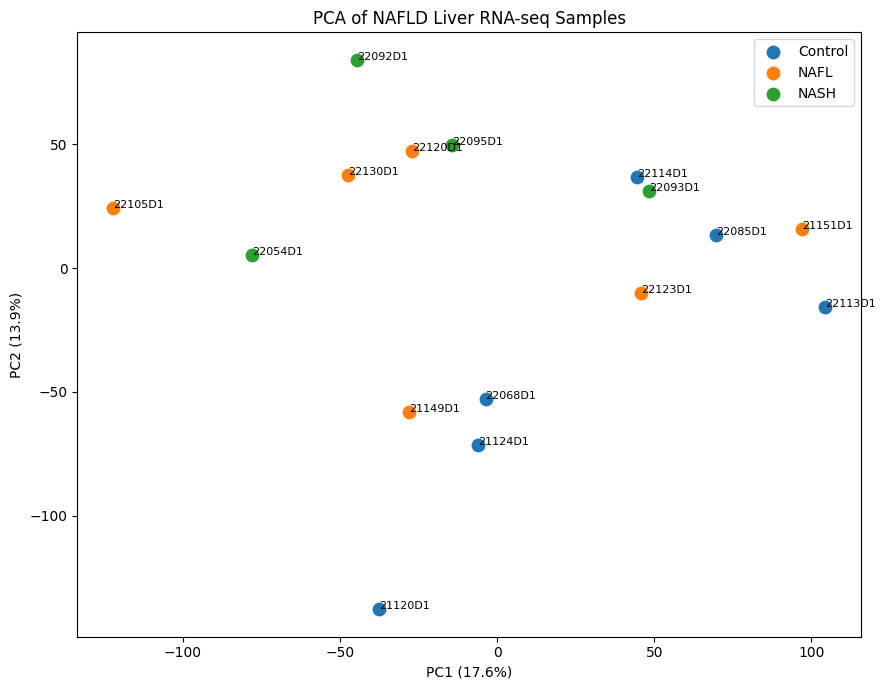

In [ ]:
plt.figure(figsize=(9, 7))

for group in pca_df["Group"].unique():
    subset = pca_df[pca_df["Group"] == group]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=group,
        s=80
    )

    for sample, row in subset.iterrows():
        plt.text(
            row["PC1"],
            row["PC2"],
            sample,
            fontsize=8
        )

plt.xlabel(f"PC1 ({explained_variance[0] * 100:.1f}%)")
plt.ylabel(f"PC2 ({explained_variance[1] * 100:.1f}%)")
plt.title("PCA of NAFLD Liver RNA-seq Samples")
plt.legend()
plt.tight_layout()
plt.show()

Remember that PCA is sample-level exploratory analysis, not differential expression.

The observations indicate that there is no clean Control-vs-NAFLD sample separation.

Control samples are spread across the PCA space rather than forming one tight cluster.

The NAFL and NASH samples are also distributed rather broadly, although some NASH happen to sit relatively close to particular controls or NAFL samples.

It is important to note that biological heterogeneity, patient-to-patient differences, technical factors, tissue characteristics may contribute substantially.

PyDESeq2's Deseq DataSet is designed to receive raw count data, with samples as rows and genes as columns, and it performs the size-factor normalization and dispersion/LFC modeling internally.

Differential Expression Analysis

Prepare the metadata column for Differential expression which is the analysis group and counting the values.

In [ ]:
metadata_de = metadata[["Analysis_Group"]].copy()

print(metadata_de)
print("\nGroup counts:")
print(metadata_de["Analysis_Group"].value_counts())

        Analysis_Group
21120D1        Control
21124D1        Control
22068D1        Control
22085D1        Control
22113D1        Control
22114D1        Control
21149D1          NAFLD
21151D1          NAFLD
22054D1          NAFLD
22092D1          NAFLD
22093D1          NAFLD
22095D1          NAFLD
22105D1          NAFLD
22120D1          NAFLD
22123D1          NAFLD
22130D1          NAFLD

Group counts:
Analysis_Group
NAFLD      10
Control     6
Name: count, dtype: int64


Making sure the transposed and filtered counts index and metadata index are aligned

In [ ]:
counts_de = counts_filtered.T.copy()

print("Counts shape:", counts_de.shape)
print("Metadata shape:", metadata_de.shape)

print(
    "Samples aligned:",
    all(counts_de.index == metadata_de.index)
)

Counts shape: (16, 21141)
Metadata shape: (16, 1)
Samples aligned: True


Importing PyDESeq2 dataset for differential expression

In [ ]:
from pydeseq2.dds import DeseqDataSet

Here the model describes gene expression from the differences according to analysis group

In [ ]:
dds = DeseqDataSet(
    counts=counts_de,
    metadata=metadata_de,
    design="~Analysis_Group",
    refit_cooks=True
)

It is important to note that PyDESeq2 uses a negative-binomial model and estimates gene-wise dispersion and log-fold changes as part of the DESeq2 workflow.

Running the DESeq2 pipeline

In [ ]:
dds.deseq2()

Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.04 seconds.

Fitting dispersions...
... done in 24.69 seconds.

Fitting dispersion trend curve...
... done in 0.55 seconds.

Fitting MAP dispersions...
... done in 33.02 seconds.

Fitting LFCs...
... done in 15.23 seconds.

Calculating cook's distance...
... done in 0.02 seconds.

Replacing 129 outlier genes.

Fitting dispersions...
... done in 0.17 seconds.

Fitting MAP dispersions...
... done in 0.18 seconds.

Fitting LFCs...
... done in 0.17 seconds.



Performing the statistical test for the DESeq2 analysis from the previous cell.

Using DESeq2 stats, NAFLD when compared with Control.
PyDESeq2's current API specifies contrasts in exactly this factor/tested-level/reference-level format.

In [ ]:
from pydeseq2.ds import DeseqStats

stat_res = DeseqStats(
    dds,
    contrast=["Analysis_Group", "NAFLD", "Control"],
    alpha=0.05
)

stat_res.summary()

Running Wald tests...
... done in 5.35 seconds.



Log2 fold change & Wald test p-value: Analysis_Group NAFLD vs Control
                baseMean  log2FoldChange     lfcSE      stat    pvalue  \
Symbol                                                                   
MT-CO1      1.778041e+06       -0.716720  0.399660 -1.793324  0.072921   
FGA         1.099861e+06        0.350333  0.305856  1.145419  0.252036   
FGB         1.060424e+06        0.005874  0.284176  0.020669  0.983510   
HP          1.042191e+06       -0.033925  0.311120 -0.109040  0.913170   
MT-ND4      8.459095e+05       -0.698465  0.340813 -2.049409  0.040422   
...                  ...             ...       ...       ...       ...   
LINC01703   2.675021e+00       -1.408556  1.819024 -0.774347  0.438726   
IGKV2-4     2.436147e+00        4.295205  2.229652  1.926402  0.054054   
IGLV9-49    2.642557e+00        1.453488  2.098566  0.692610  0.488554   
AP001610.2  2.189514e+00       -0.398365  1.714358 -0.232370  0.816251   
AC093725.2  2.067697e+00       -0.324321  

DE results
   ↓
inspect results
   ↓
significant genes
   ↓
up/down-regulated genes
   ↓
MA plot
   ↓
volcano plot
   ↓
top-gene heatmap
   ↓
GO/KEGG pathway analysis

Printe the shape of the differential expression and PyDESeq2 statistical results.

In [ ]:
de_results = stat_res.results_df.copy()

print("DE results shape:", de_results.shape)

de_results.head()

DE results shape: (21141, 6)


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
Symbol,,,,,,
MT-CO1,1.778041e+06,-0.716720,0.399660,-1.793324,0.072921,0.450112
FGA,1.099861e+06,0.350333,0.305856,1.145419,0.252036,0.670340
FGB,1.060424e+06,0.005874,0.284176,0.020669,0.983510,0.995745
HP,1.042191e+06,-0.033925,0.311120,-0.109040,0.913170,0.978480
MT-ND4,8.459095e+05,-0.698465,0.340813,-2.049409,0.040422,0.375524


The important columns here are:

• baseMean — average normalized expression

• log2FoldChange — direction and magnitude of change

• pvalue — statistical significance before multiple-testing correction

• padj — multiple-testing-adjusted p-value

PyDESeq2 also reports the LFC in log2 scale.

Sorting by multiple-testing-adjusted p-value(padj)

In [ ]:
de_results_sorted = de_results.sort_values("padj")

de_results_sorted.head(20)

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
Symbol,,,,,,
CHRD,6929.979883,-1.445428,0.224531,-6.437544,1.214219e-10,0.000001
TMEM154,259.949545,3.542196,0.542419,6.530367,6.560863e-11,0.000001
HKDC1,463.435160,3.194360,0.570702,5.597245,2.177843e-08,0.000132
HGFAC,3713.958610,-1.472019,0.270094,-5.450034,5.036026e-08,0.000230
KLHL29,464.350328,2.384885,0.453650,5.257099,1.463459e-07,0.000534
MACROH2A2,163.966538,2.150850,0.414324,5.191227,2.089130e-07,0.000549
LMNTD2-AS1,141.487213,-1.786024,0.344157,-5.189558,2.107939e-07,0.000549
MIR1244-1,110.764157,7.353276,1.455256,5.052907,4.351357e-07,0.000992
RGS11,74.240749,-1.771988,0.356050,-4.976793,6.464641e-07,0.001309


The first thing to notice is that the top genes have very small adjusted p-values.

The contrast here was,
NAFLD vs Control

So:
positive log2FoldChange is higher in NAFLD
negative log2FoldChange is lower in NAFLD


The padj is particularly important because thousands of genes are being tested simultaneously and PyDESeq2's results dataframe contains the multiple-testing-adjusted p-values(padj)

For instance, TMEM154
A log2FC of +3.54 means:
2^3.54 ≈ 11.6

So, according to this model, its estimated expression is roughly 11.6-fold higher in NAFLD than Control.


For CHRD
2^-1.45 ≈ 0.37
So its expression in NAFLD is roughly 37% of the Control level, corresponding to about a 63% decrease.

Checking the differential expression count for significant genes

For significant genes, use:
padj < 0.05
|log2FoldChange| >= 1

In [ ]:
significant_de = de_results[
    (de_results["padj"] < 0.05) &
    (de_results["log2FoldChange"].abs() >= 1)
].copy()

print("Significant DEGs:", significant_de.shape[0])

Significant DEGs: 64


Counting the upregulated and downregulated genes from the significant genes count.

In [ ]:
upregulated = significant_de[
    significant_de["log2FoldChange"] > 0
].sort_values("padj")

downregulated = significant_de[
    significant_de["log2FoldChange"] < 0
].sort_values("padj")

print("Upregulated:", len(upregulated))
print("Downregulated:", len(downregulated))

Upregulated: 31
Downregulated: 33


Looking at the top upregulated genes.

In [ ]:
print("Top upregulated genes:")
display(upregulated.head(20))

Top upregulated genes:


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
Symbol,,,,,,
TMEM154,259.949545,3.542196,0.542419,6.530367,6.560863e-11,0.000001
HKDC1,463.435160,3.194360,0.570702,5.597245,2.177843e-08,0.000132
KLHL29,464.350328,2.384885,0.453650,5.257099,1.463459e-07,0.000534
MACROH2A2,163.966538,2.150850,0.414324,5.191227,2.089130e-07,0.000549
MIR1244-1,110.764157,7.353276,1.455256,5.052907,4.351357e-07,0.000992
ZC3H11A,1884.519080,2.851101,0.604574,4.715881,2.406674e-06,0.003989
MRAS,85.078414,2.668412,0.580331,4.598088,4.263868e-06,0.005979
ACKR3,179.005710,1.809671,0.396320,4.566182,4.966868e-06,0.006036
TMEM92,65.180584,3.486275,0.762237,4.573739,4.790974e-06,0.006036


Looking at the top downregulated genes

In [ ]:
print("Top downregulated genes:")
display(downregulated.head(20))

Top downregulated genes:


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
Symbol,,,,,,
CHRD,6929.979883,-1.445428,0.224531,-6.437544,1.214219e-10,0.000001
HGFAC,3713.958610,-1.472019,0.270094,-5.450034,5.036026e-08,0.000230
LMNTD2-AS1,141.487213,-1.786024,0.344157,-5.189558,2.107939e-07,0.000549
RGS11,74.240749,-1.771988,0.356050,-4.976793,6.464641e-07,0.001309
CUTALP,293.806327,-2.552672,0.527554,-4.838693,1.306959e-06,0.002383
AL121827.1,88.131629,-2.069658,0.449177,-4.607664,4.072179e-06,0.005979
SSPO,74.535193,-2.115842,0.466687,-4.533745,5.794689e-06,0.006602
AZGP1P1,875.612354,-1.307550,0.295432,-4.425891,9.604505e-06,0.009727
EP400P1,471.538674,-1.972217,0.465675,-4.235181,2.283680e-05,0.015596


Saving the complete DE results

In [ ]:
de_results_path = "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/data/DE_results_NAFLD_vs_Control.csv"

de_results.to_csv(de_results_path)

print("Saved:", de_results_path)

Saved: /content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/data/DE_results_NAFLD_vs_Control.csv


In [ ]:
sig_path = "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/data/significant_DEGs_NAFLD_vs_Control.csv"

significant_de.to_csv(sig_path)

print("Saved:", sig_path)

Saved: /content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/data/significant_DEGs_NAFLD_vs_Control.csv


Describing the DE results counts and percentage

In [ ]:
print("Total genes tested:", len(de_results))
print("Significant DEGs:", len(significant_de))
print("Upregulated:", len(upregulated))
print("Downregulated:", len(downregulated))

Total genes tested: 21141
Significant DEGs: 64
Upregulated: 31
Downregulated: 33


In [ ]:
print("Percentage of genes significant:",
      len(significant_de) / len(de_results) * 100)

Percentage of genes significant: 0.30272929378931934


Looking at the top 20 upregulated and down regulated genes

In [ ]:
upregulated.head(20)

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
Symbol,,,,,,
TMEM154,259.949545,3.542196,0.542419,6.530367,6.560863e-11,0.000001
HKDC1,463.435160,3.194360,0.570702,5.597245,2.177843e-08,0.000132
KLHL29,464.350328,2.384885,0.453650,5.257099,1.463459e-07,0.000534
MACROH2A2,163.966538,2.150850,0.414324,5.191227,2.089130e-07,0.000549
MIR1244-1,110.764157,7.353276,1.455256,5.052907,4.351357e-07,0.000992
ZC3H11A,1884.519080,2.851101,0.604574,4.715881,2.406674e-06,0.003989
MRAS,85.078414,2.668412,0.580331,4.598088,4.263868e-06,0.005979
ACKR3,179.005710,1.809671,0.396320,4.566182,4.966868e-06,0.006036
TMEM92,65.180584,3.486275,0.762237,4.573739,4.790974e-06,0.006036


In [ ]:
downregulated.head(20)

,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj
Symbol,,,,,,
CHRD,6929.979883,-1.445428,0.224531,-6.437544,1.214219e-10,0.000001
HGFAC,3713.958610,-1.472019,0.270094,-5.450034,5.036026e-08,0.000230
LMNTD2-AS1,141.487213,-1.786024,0.344157,-5.189558,2.107939e-07,0.000549
RGS11,74.240749,-1.771988,0.356050,-4.976793,6.464641e-07,0.001309
CUTALP,293.806327,-2.552672,0.527554,-4.838693,1.306959e-06,0.002383
AL121827.1,88.131629,-2.069658,0.449177,-4.607664,4.072179e-06,0.005979
SSPO,74.535193,-2.115842,0.466687,-4.533745,5.794689e-06,0.006602
AZGP1P1,875.612354,-1.307550,0.295432,-4.425891,9.604505e-06,0.009727
EP400P1,471.538674,-1.972217,0.465675,-4.235181,2.283680e-05,0.015596


The threshold was:
padj < 0.05
|log2FC| ≥ 1

So the 64 significant genes satisfy both criteria.

PyDESeq2's padj is the multiple-testing-adjusted p-value, and its results table reports LFCs on the log2 scale.

The strongest positive changes includes;
TMEM154 — log2FC +3.54
HKDC1 — +3.19
KLHL29 — +2.38
MACROH2A2 — +2.15
MIR1244-1 — +7.35

And strongest negative changes include:
CHRD — −1.45
HGFAC — −1.47
LMNTD2-AS1 — −1.79
RGS11 — −1.77
CUTALP — −2.55
SSPO — −2.12

It is necessary to note that MIR1244-1 (+7.35) result is particularly large.

MA plot

Plotting the statistical results using an MA plot.

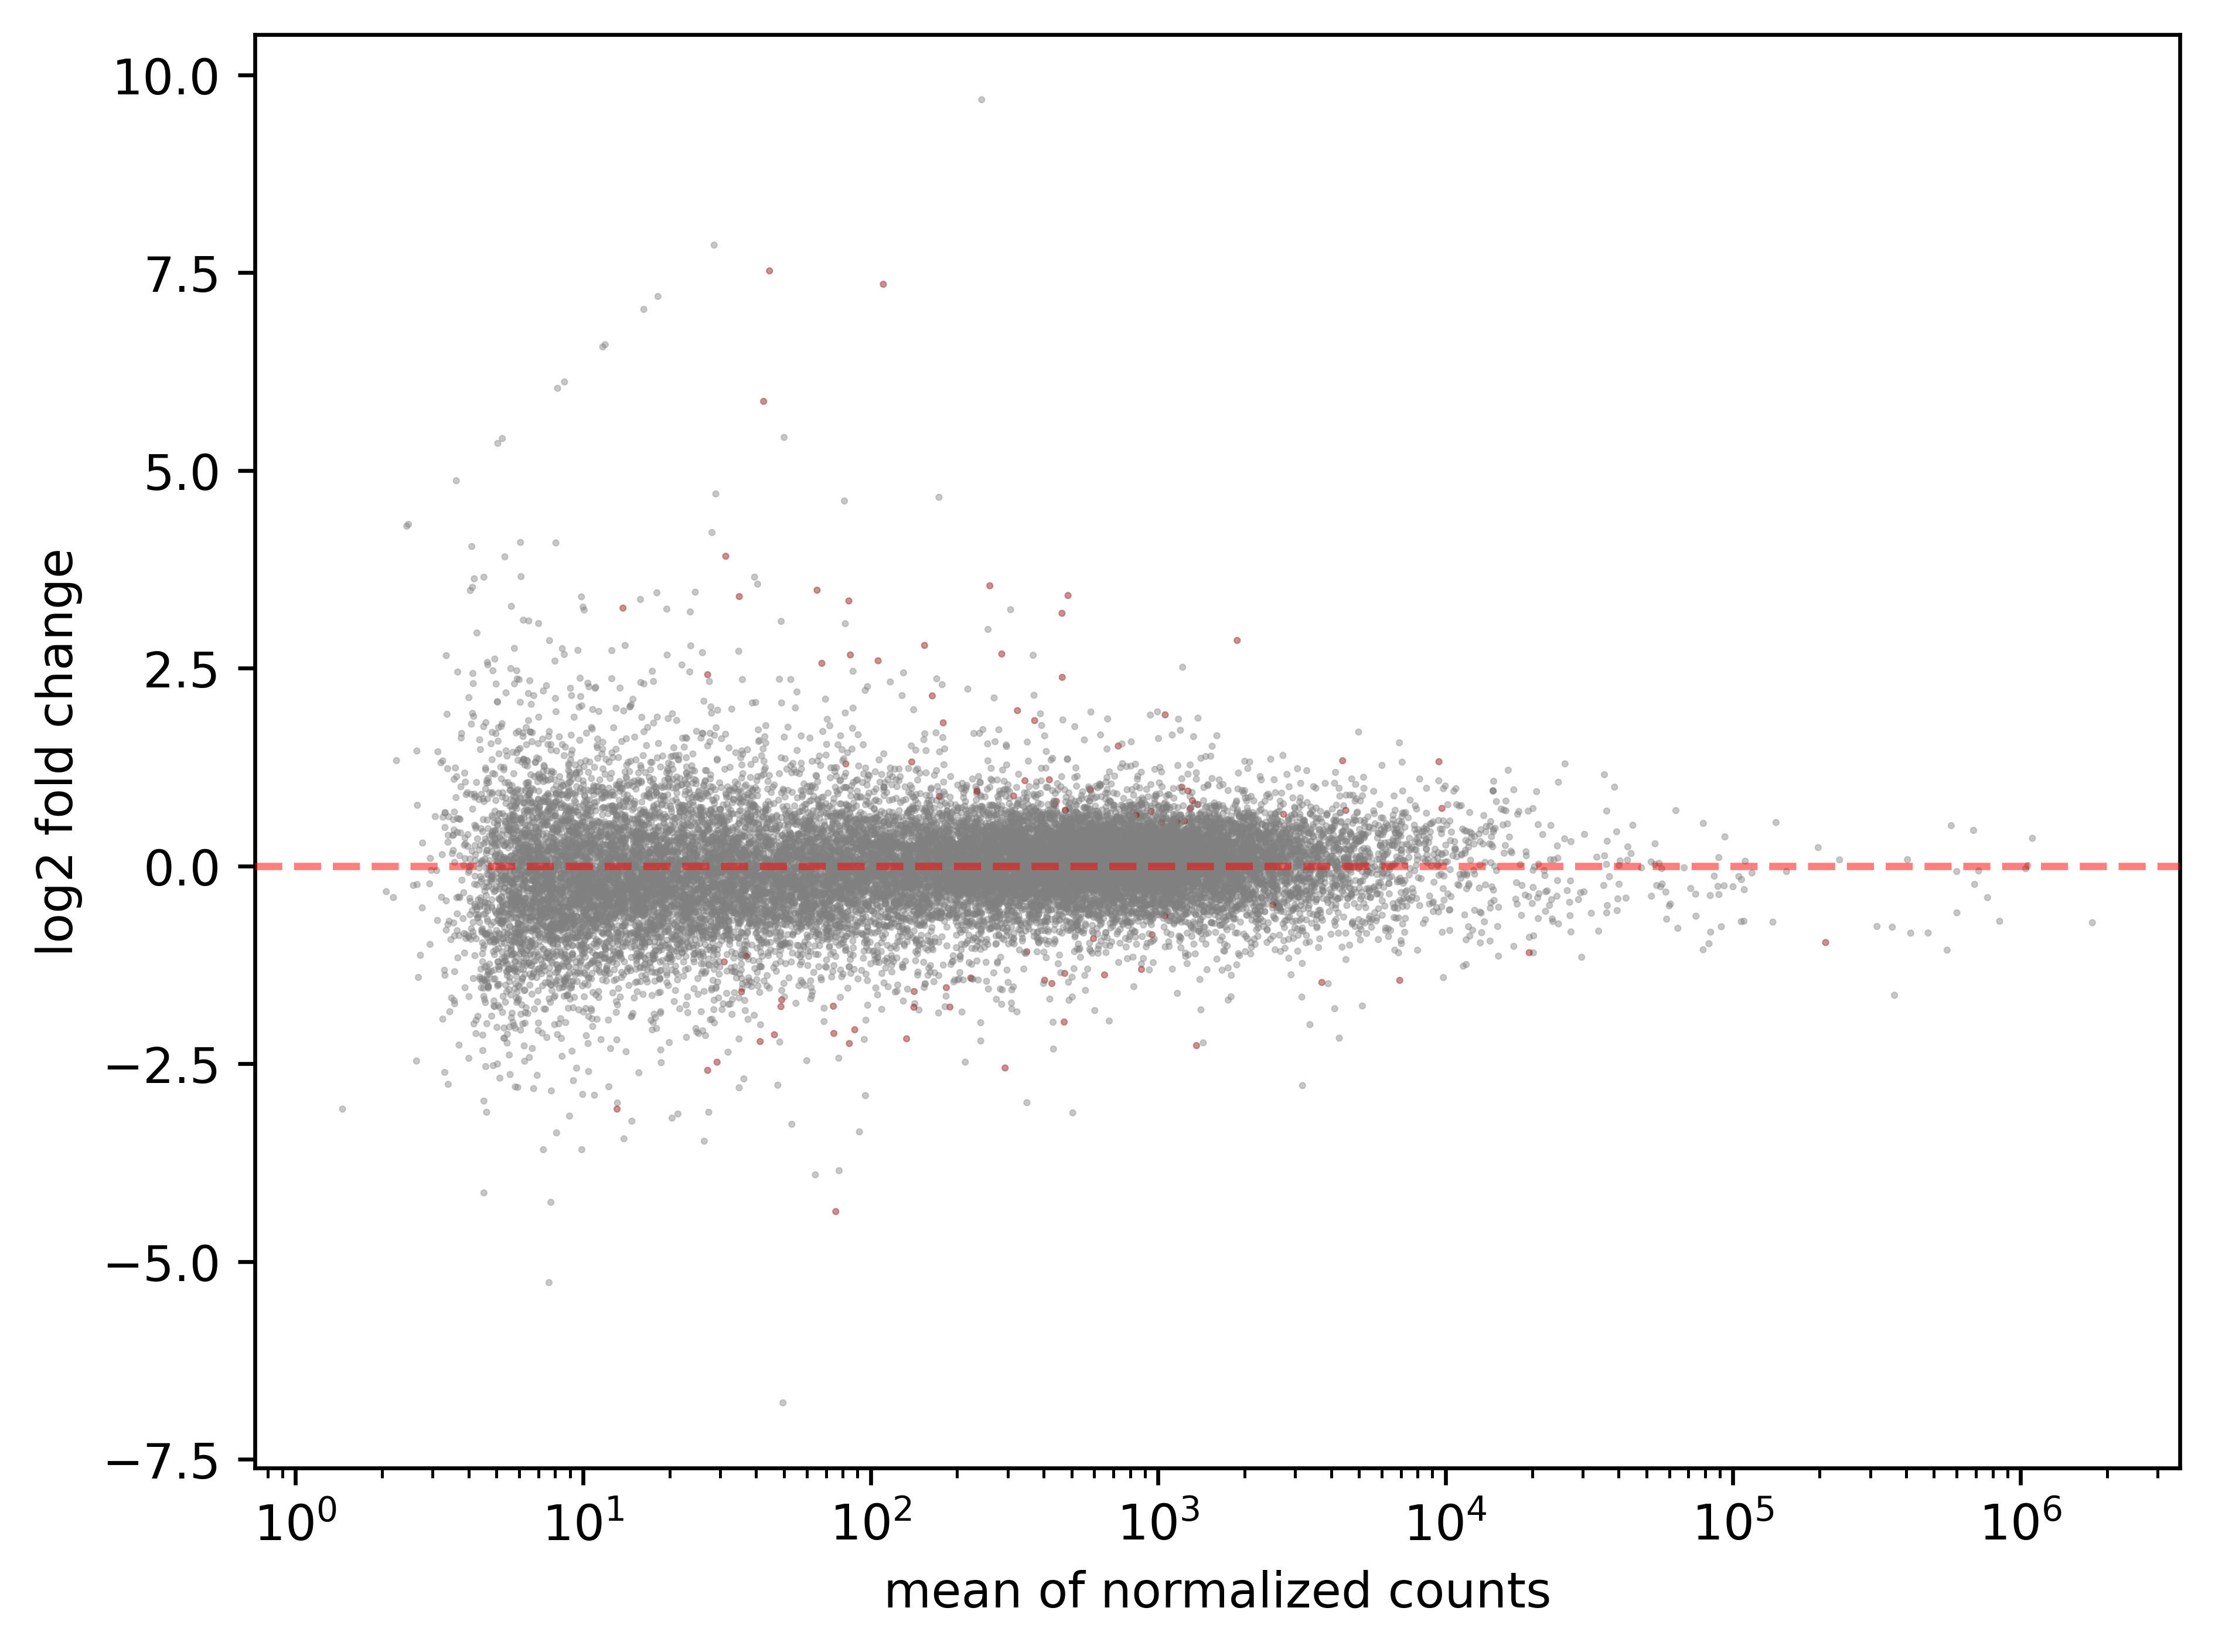

In [ ]:
stat_res.plot_MA()
plt.show()

1. What an MA plot is showing us:

X-axis — mean of normalized counts(How highly expressed is the gene overall?)

Y-axis — log2 fold change (How much does its expression differ between NAFLD and Control?)

So each dot is one gene.
The red dashed horizontal line at 0 means no difference in expression between NAFLD and Control.

Genes above 0 → higher in NAFLD
Genes below 0 → lower in NAFLD.

2. What this particular plot tells us:

The overwhelming majority of genes are clustered close to 0 because most genes do not undergo large expression changes simply because a sample is NAFLD.

There is also a relatively small number of points extending far above and below zero and these are genes with larger expression differences.

Based on what was already established:

For example, TMEM154, with log2FC ≈ +3.54, would appear substantially above the zero line, while CHRD, with log2FC ≈ −1.45, would appear below it.


The spread is generally wider at low expression and becomes narrower as you move toward higher counts which is common in RNA-seq data.
Genes with very low counts have more variability relative to their expression level, so more extreme fold changes among those genes.


The majority of genes from the MA plot show relatively small expression differences between NAFLD and controls, while a smaller subset exhibits substantial differential expression.

Volcano plot

Preparing the differential expression data for volcanic plot.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

volcano = de_results.copy()

# Convert adjusted p-values to -log10 scale
volcano["-log10_padj"] = -np.log10(
    volcano["padj"].clip(lower=1e-300)
)

# Classify genes
volcano["Significance"] = "Not significant"

volcano.loc[
    (volcano["padj"] < 0.05) &
    (volcano["log2FoldChange"] >= 1),
    "Significance"
] = "Upregulated"

volcano.loc[
    (volcano["padj"] < 0.05) &
    (volcano["log2FoldChange"] <= -1),
    "Significance"
] = "Downregulated"

print(volcano["Significance"].value_counts())

Significance
Not significant    21077
Downregulated         33
Upregulated           31
Name: count, dtype: int64


Plotting the volcano plot

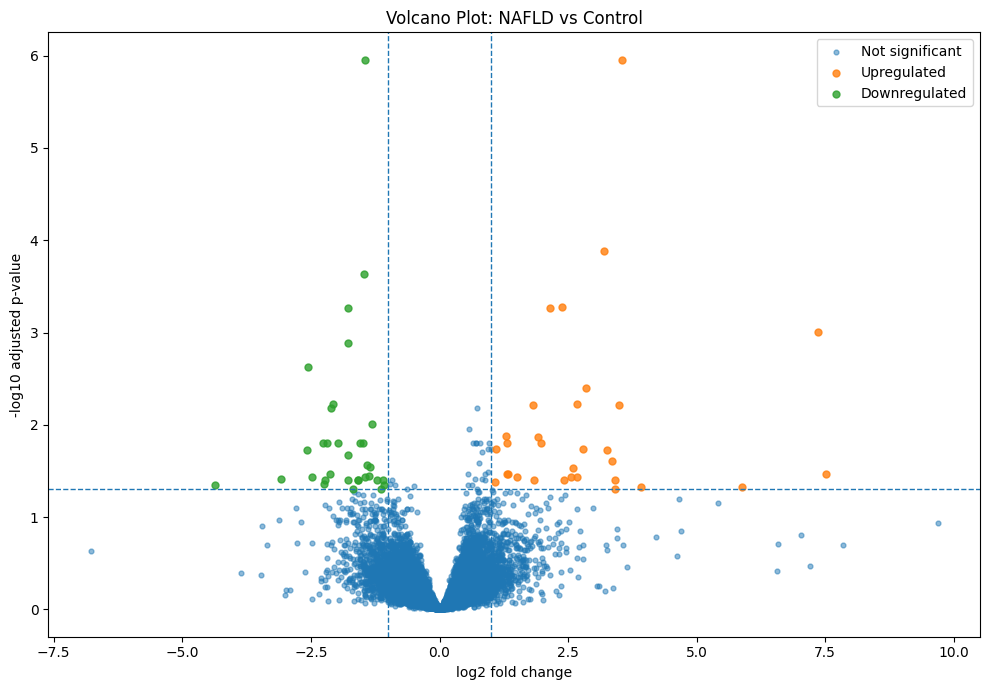

In [ ]:
plt.figure(figsize=(10, 7))

# Plot not significant genes
ns = volcano[volcano["Significance"] == "Not significant"]

plt.scatter(
    ns["log2FoldChange"],
    ns["-log10_padj"],
    s=12,
    alpha=0.5,
    label="Not significant"
)

# Plot upregulated genes
up = volcano[volcano["Significance"] == "Upregulated"]

plt.scatter(
    up["log2FoldChange"],
    up["-log10_padj"],
    s=25,
    alpha=0.8,
    label="Upregulated"
)

# Plot downregulated genes
down = volcano[volcano["Significance"] == "Downregulated"]

plt.scatter(
    down["log2FoldChange"],
    down["-log10_padj"],
    s=25,
    alpha=0.8,
    label="Downregulated"
)

# Threshold lines
plt.axvline(
    x=1,
    linestyle="--",
    linewidth=1
)

plt.axvline(
    x=-1,
    linestyle="--",
    linewidth=1
)

plt.axhline(
    y=-np.log10(0.05),
    linestyle="--",
    linewidth=1
)

plt.xlabel("log2 fold change")
plt.ylabel("-log10 adjusted p-value")
plt.title("Volcano Plot: NAFLD vs Control")
plt.legend()

plt.tight_layout()
plt.show()

The volcano plot combines effect size and statistical significance in this way:

• X-axis: log2 fold change

• Right = higher in NAFLD

• Left = lower in NAFLD

• Y-axis: −log10(adjusted p-value)
• Higher = stronger statistical evidence

The vertical dashed lines at −1 and +1 correspond to your |log2FC| ≥ 1 threshold.

The horizontal line corresponds to padj = 0.05.

The plot shows a fairly clear set of significant genes on both sides.

31 upregulated genes
33 downregulated genes
64 genes total meeting both padj < 0.05 and |log2FC| ≥ 1.

There are also some genes with very large fold changes, particularly on the right side.

Again, some low-expression genes can produce very large fold changes.

Heatmap

Select the top 20 genes(10 upregulated and 10 downregulated)

In [ ]:
# Top 10 upregulated genes
top_up = (
    upregulated
    .sort_values("padj")
    .head(10)
)

# Top 10 downregulated genes
top_down = (
    downregulated
    .sort_values("padj")
    .head(10)
)

top_genes = list(top_up.index) + list(top_down.index)

print("Top genes:")
print(top_genes)

Top genes:
['TMEM154', 'HKDC1', 'KLHL29', 'MACROH2A2', 'MIR1244-1', 'ZC3H11A', 'MRAS', 'ACKR3', 'TMEM92', 'PACC1', 'CHRD', 'HGFAC', 'LMNTD2-AS1', 'RGS11', 'CUTALP', 'AL121827.1', 'SSPO', 'AZGP1P1', 'EP400P1', 'NUDT13']


Printing the top genes and their normalized expression's shape and metadata.

In [ ]:
heatmap_data = normalized_counts[top_genes].copy()

print("Heatmap data shape:", heatmap_data.shape)
heatmap_data.head()

Heatmap data shape: (16, 20)


Symbol,TMEM154,HKDC1,KLHL29,MACROH2A2,MIR1244-1,ZC3H11A,MRAS,ACKR3,TMEM92,PACC1,CHRD,HGFAC,LMNTD2-AS1,RGS11,CUTALP,AL121827.1,SSPO,AZGP1P1,EP400P1,NUDT13
21120D1,41.694903,69.491505,157.157711,48.109503,1.069100,100.495407,23.520202,39.556703,17.105601,22.451102,13493.112074,6479.815568,210.612715,130.430209,233.063817,231.994717,159.295911,2393.715073,1927.587439,439.400132
21124D1,50.306283,146.345550,213.801702,61.739529,1.143325,329.277487,12.576571,114.332461,3.429974,65.169503,18109.118487,6798.208127,492.772907,254.961388,1222.214007,91.465969,126.909032,1329.686521,288.117802,460.759818
22068D1,27.017334,105.991079,124.695387,41.565129,1.039128,383.438315,21.821693,70.660719,6.234769,22.860821,8030.382928,7758.131333,279.525493,59.230309,803.246118,142.360567,100.795438,999.641353,172.495285,244.195133
22085D1,32.437951,58.197500,117.349057,44.840697,0.954057,625.861637,15.264918,46.748811,0.000000,52.473156,10503.217624,5420.953996,185.087130,122.119344,1095.257865,244.238688,74.416475,1053.279340,1942.460812,403.566269
22113D1,12.034662,40.480227,35.009926,43.762407,1.094060,522.960768,24.069324,62.361431,10.940602,28.445565,12298.330541,6720.811717,172.861509,161.920907,165.203088,115.970380,268.044745,1496.674333,713.327241,134.569403


Log-transforming the heatmap data normalized counts

In [ ]:
heatmap_log = np.log2(heatmap_data + 1)

heatmap_log.head()

Symbol,TMEM154,HKDC1,KLHL29,MACROH2A2,MIR1244-1,ZC3H11A,MRAS,ACKR3,TMEM92,PACC1,CHRD,HGFAC,LMNTD2-AS1,RGS11,CUTALP,AL121827.1,SSPO,AZGP1P1,EP400P1,NUDT13
21120D1,5.415992,6.139378,7.305220,5.617930,1.049003,6.665271,4.615899,5.341868,4.178364,4.551584,13.720042,12.661960,7.725283,7.038153,7.870758,7.864153,7.324594,11.225638,10.913329,8.782671
21124D1,5.681064,7.203060,7.746862,5.971303,1.099850,8.367535,3.763047,6.849655,2.147298,6.048095,14.144508,12.731151,8.947704,7.999782,10.256461,6.530851,6.998974,10.377955,8.175514,8.850999
22068D1,4.808248,6.741347,6.973788,5.411600,1.027952,8.586608,4.512334,6.163111,2.854947,4.576572,12.971433,12.921679,8.131988,5.912418,9.651493,7.163504,6.669529,9.966709,7.438753,7.937787
22085D1,5.063415,5.887464,6.886904,5.518557,0.966473,9.292003,4.023692,5.577393,0.000000,5.740743,13.358681,12.404597,7.539834,6.943914,10.098371,7.938043,6.236808,10.042041,10.924412,8.660232
22113D1,3.704281,5.374352,5.170323,5.484216,1.066303,9.033315,4.647851,5.985533,3.577804,4.879978,13.586292,12.714634,7.441795,7.348028,7.376803,6.869999,8.071702,10.548508,9.480441,7.082888


Z-score each gene

The z-score checks if a gene is relatively highly or lowly expressed in each sample when compared with it's expression across all samples.

In [ ]:
from scipy.stats import zscore

heatmap_z = heatmap_log.apply(zscore, axis=0)

heatmap_z.head()

Symbol,TMEM154,HKDC1,KLHL29,MACROH2A2,MIR1244-1,ZC3H11A,MRAS,ACKR3,TMEM92,PACC1,CHRD,HGFAC,LMNTD2-AS1,RGS11,CUTALP,AL121827.1,SSPO,AZGP1P1,EP400P1,NUDT13
21120D1,-0.790787,-0.882112,-0.623996,-0.895667,-0.557797,-1.656405,-0.580466,-1.587902,-0.211443,-1.962549,1.542772,1.199073,0.912395,1.147021,0.384503,1.410269,1.173280,1.996158,2.266919,1.597386
21124D1,-0.650501,-0.305242,-0.321331,-0.639374,-0.542330,-0.754561,-1.105714,-0.213393,-1.182374,-0.155627,2.095039,1.277108,2.068927,2.070616,1.907891,0.464890,0.950527,0.994855,-0.072631,1.665234
22068D1,-1.112428,-0.555644,-0.851132,-1.045314,-0.564201,-0.638498,-0.644249,-0.839252,-0.844090,-1.932378,0.568766,1.491988,1.297178,0.065810,1.521589,0.913473,0.725157,0.509082,-0.702217,0.758430
22085D1,-0.977384,-1.018733,-0.910675,-0.967740,-0.582903,-0.264787,-0.945190,-1.373196,-2.208869,-0.526731,1.072610,0.908817,0.736942,1.056509,1.806943,1.462660,0.429137,0.598066,2.276390,1.475806
22113D1,-1.696689,-1.297011,-2.087078,-0.992647,-0.552535,-0.401837,-0.560788,-1.001133,-0.498535,-1.566038,1.368751,1.258481,0.644187,1.444639,0.069089,0.705364,1.684369,1.196316,1.042471,-0.090469


Plotting the heatmap of the 20 top genes

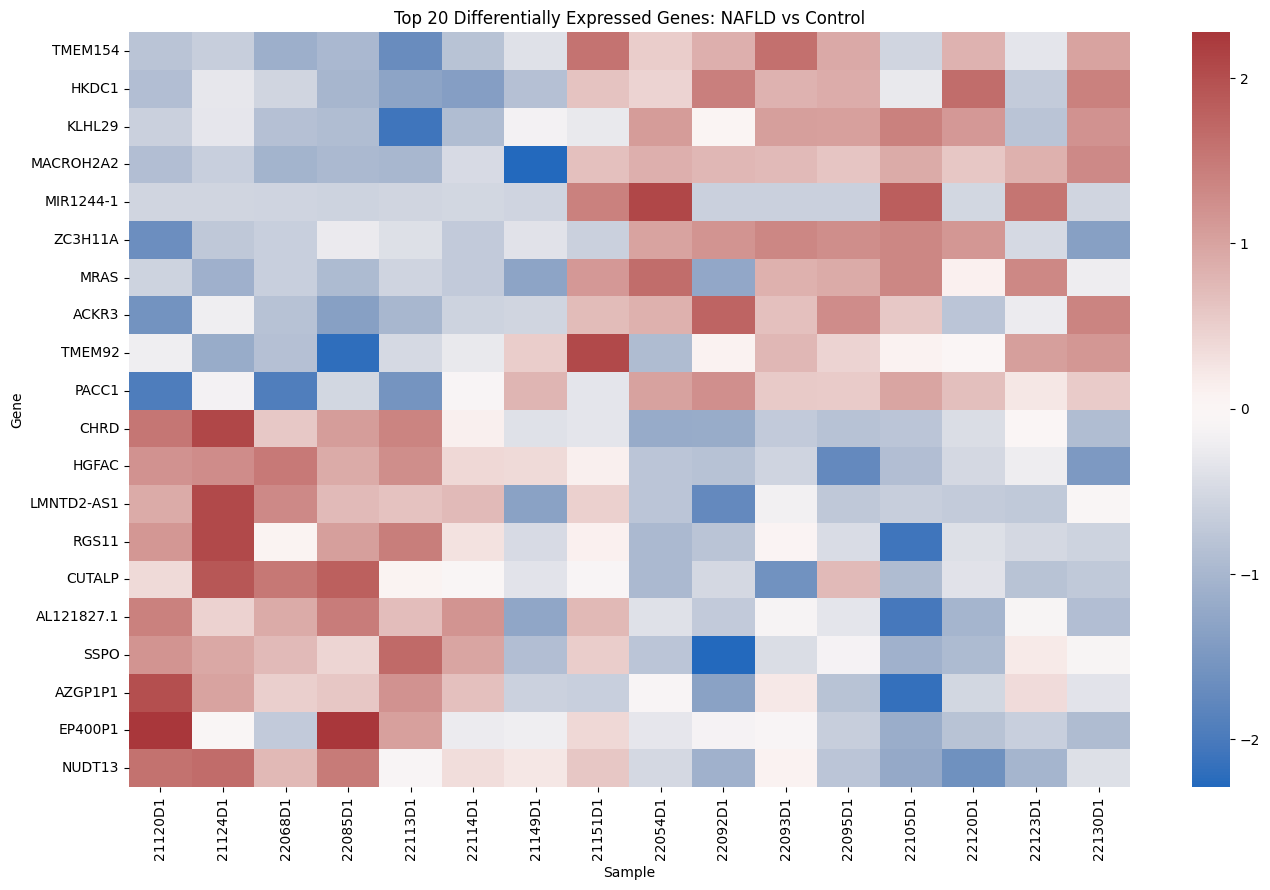

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 9))

sns.heatmap(
    heatmap_z.T,
    cmap="vlag",
    center=0,
    xticklabels=True,
    yticklabels=True
)

plt.xlabel("Sample")
plt.ylabel("Gene")
plt.title("Top 20 Differentially Expressed Genes: NAFLD vs Control")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

A Group annotation Heatmap

To create a group annotation heatmaps, we confirm the labels from the metadata analysis group.

In [ ]:
print(metadata["Analysis_Group"].value_counts())

Analysis_Group
NAFLD      10
Control     6
Name: count, dtype: int64


Printing the shapes of the heatmap features

In [ ]:
print("heatmap_z shape:", heatmap_z.shape)
print("heatmap_z index:", heatmap_z.index[:5])
print("heatmap_z columns:", heatmap_z.columns[:5])

heatmap_z shape: (16, 20)
heatmap_z index: Index(['21120D1', '21124D1', '22068D1', '22085D1', '22113D1'], dtype='str')
heatmap_z columns: Index(['TMEM154', 'HKDC1', 'KLHL29', 'MACROH2A2', 'MIR1244-1'], dtype='str', name='Symbol')


Reprinting the sample group and analysis group for the heatmap group annotation

In [ ]:
sample_groups = metadata.loc[heatmap_z.index, "Analysis_Group"]

print(sample_groups)

21120D1    Control
21124D1    Control
22068D1    Control
22085D1    Control
22113D1    Control
22114D1    Control
21149D1      NAFLD
21151D1      NAFLD
22054D1      NAFLD
22092D1      NAFLD
22093D1      NAFLD
22095D1      NAFLD
22105D1      NAFLD
22120D1      NAFLD
22123D1      NAFLD
22130D1      NAFLD
Name: Analysis_Group, dtype: str


Plotting the annotated heatmap

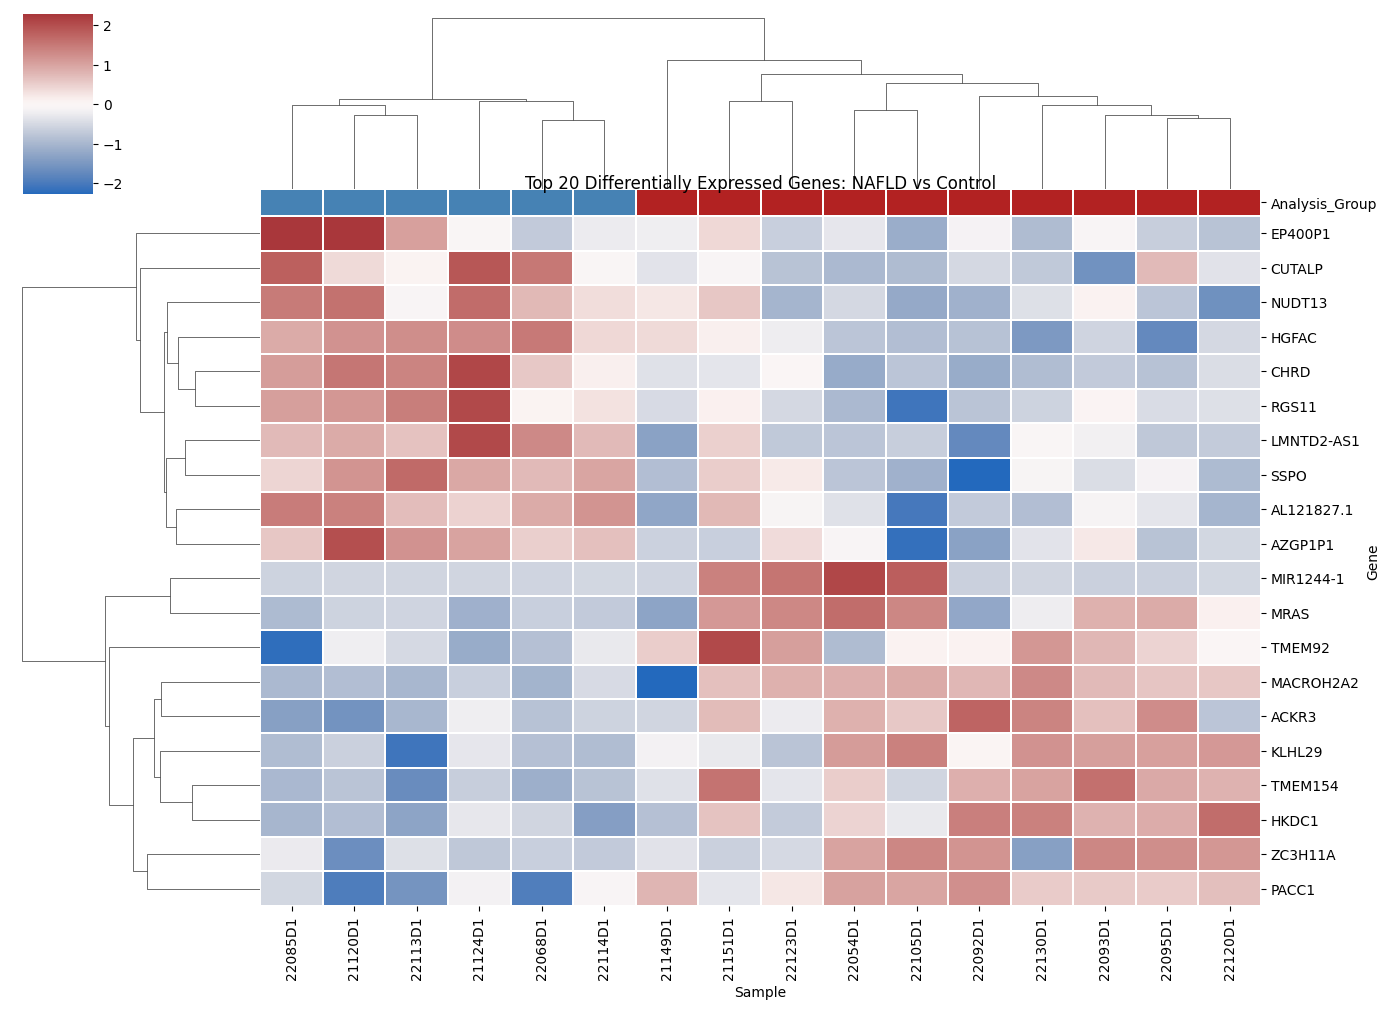

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Get group labels in the same order as the samples
sample_groups = metadata.loc[heatmap_z.index, "Analysis_Group"]

# Convert groups to colors
group_colors = sample_groups.map({
    "Control": "steelblue",
    "NAFLD": "firebrick"
})

# Transpose so genes are rows and samples are columns
heatmap_for_plot = heatmap_z.T

# Create clustered heatmap
g = sns.clustermap(
    heatmap_for_plot,
    cmap="vlag",
    center=0,
    col_colors=group_colors,
    figsize=(14, 10),
    xticklabels=True,
    yticklabels=True,
    linewidths=0.3
)

g.ax_heatmap.set_xlabel("Sample")
g.ax_heatmap.set_ylabel("Gene")

g.ax_heatmap.set_title(
    "Top 20 Differentially Expressed Genes: NAFLD vs Control",
    pad=20
)

plt.setp(
    g.ax_heatmap.get_xticklabels(),
    rotation=90
)

plt.show()

GO enrichment

Performing GO enrichment separately for upregulated and downregulated genes, rather than throwing all 64 DEGs together to preserve the biological direction of the result.

Using gseapy with Enrichr

Printing the differential expression data column

In [ ]:
print(de_results.columns.tolist())

['baseMean', 'log2FoldChange', 'lfcSE', 'stat', 'pvalue', 'padj']


In [ ]:
print(de_results.head())

            baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
Symbol                                                                      
MT-CO1  1.778041e+06       -0.716720  0.399660 -1.793324  0.072921  0.450112
FGA     1.099861e+06        0.350333  0.305856  1.145419  0.252036  0.670340
FGB     1.060424e+06        0.005874  0.284176  0.020669  0.983510  0.995745
HP      1.042191e+06       -0.033925  0.311120 -0.109040  0.913170  0.978480
MT-ND4  8.459095e+05       -0.698465  0.340813 -2.049409  0.040422  0.375524


Installing the gseapy

In [ ]:
!pip install gseapy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 689.7/689.7 kB 7.4 MB/s eta 0:00:00


Printing the version of the gseapy installed

In [ ]:
import gseapy as gp

print("gseapy version:", gp.__version__)

gseapy version: 1.3.1


Printing the GO enrichment upregulated genes

In [ ]:
up_gene_symbols = upregulated.index.tolist()

print("Number of upregulated genes:", len(up_gene_symbols))
print(up_gene_symbols)

Number of upregulated genes: 31
['TMEM154', 'HKDC1', 'KLHL29', 'MACROH2A2', 'MIR1244-1', 'ZC3H11A', 'MRAS', 'ACKR3', 'TMEM92', 'PACC1', 'LAPTM4B', 'PGAP4', 'LARP6', 'ZDHHC2', 'B3GNT5', 'ELFN2', 'AP000331.1', 'NPTX2', 'ANXA5', 'PRAMEF33', 'MSN', 'TMEM263', 'B3GNT3', 'SMOX', 'LOXL4', 'S1PR2', 'IGKV3D-15', 'SGCB', 'AC023055.1', 'TRIM40', 'LINC01426']


Printing the GO enrichment of upregulated gene results.

In [ ]:
go_up = gp.enrichr(
    gene_list=up_gene_symbols,
    gene_sets="GO_Biological_Process_2023",
    organism="human",
    outdir=None
)

print("GO terms returned:", len(go_up.results))

go_up.results.head(15)

GO terms returned: 197


,Gene_set,Term,Overlap,P-value,Adjusted P-value,Old P-value,Old Adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2023,Regulation Of Protein Catabolic Process (GO:00...,3/122,0.000879,0.085365,0,0,17.872149,125.768418,TRIM40;MSN;ZDHHC2
1,GO_Biological_Process_2023,O-glycan Processing (GO:0016266),2/41,0.001836,0.085365,0,0,35.243148,222.035975,B3GNT5;B3GNT3
2,GO_Biological_Process_2023,Glycolipid Biosynthetic Process (GO:0009247),2/43,0.002018,0.085365,0,0,33.520606,208.016370,PGAP4;B3GNT5
3,GO_Biological_Process_2023,Protein Lipidation (GO:0006497),2/62,0.004149,0.085365,0,0,22.883908,125.513296,PGAP4;ZDHHC2
4,GO_Biological_Process_2023,Protein Localization To Membrane Raft (GO:1903...,1/5,0.007727,0.085365,0,0,166.375000,809.093963,ZDHHC2
5,GO_Biological_Process_2023,poly-N-acetyllactosamine Metabolic Process (GO...,1/5,0.007727,0.085365,0,0,166.375000,809.093963,B3GNT3
6,GO_Biological_Process_2023,Regulation Of Lysosome Organization (GO:1905671),1/5,0.007727,0.085365,0,0,166.375000,809.093963,LAPTM4B
7,GO_Biological_Process_2023,Regulation Of mRNA Binding (GO:1902415),1/5,0.007727,0.085365,0,0,166.375000,809.093963,LARP6
8,GO_Biological_Process_2023,Response To Testosterone (GO:0033574),1/5,0.007727,0.085365,0,0,166.375000,809.093963,MSN
9,GO_Biological_Process_2023,Positive Regulation Of Endothelial Cell Develo...,1/5,0.007727,0.085365,0,0,166.375000,809.093963,S1PR2


Printing the top background genes, i.e., non-significant genes

In [ ]:
# All genes that were tested in the differential expression analysis
background_genes = de_results.index.tolist()

print("Background genes:", len(background_genes))
print(background_genes[:10])

Background genes: 21141
['MT-CO1', 'FGA', 'FGB', 'HP', 'MT-ND4', 'ALB', 'ORM1', 'FGG', 'SERPINA1', 'MT-CO3']


Confirming the upregulated and downregulated genes

In [ ]:
up_gene_symbols = upregulated.index.tolist()
down_gene_symbols = downregulated.index.tolist()

print("Upregulated genes:", len(up_gene_symbols))
print("Downregulated genes:", len(down_gene_symbols))

Upregulated genes: 31
Downregulated genes: 33


Running the differentially expressed genes (DEGs) which is 31 upregulated genes when compared against the 21,141 background genes that were actually tested

In [ ]:
go_up = gp.enrichr(
    gene_list=up_gene_symbols,
    gene_sets="GO_Biological_Process_2023",
    organism="human",
    background=background_genes,
    outdir=None
)

print("GO terms returned:", len(go_up.results))

go_up.results.head(15)

GO terms returned: 197


,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2023,Regulation Of Protein Catabolic Process (GO:00...,0.000599,0.071707,0,0,20.454545,151.769001,TRIM40;MSN;ZDHHC2
1,GO_Biological_Process_2023,O-glycan Processing (GO:0016266),0.001271,0.071707,0,0,42.750507,285.063737,B3GNT5;B3GNT3
2,GO_Biological_Process_2023,Glycolipid Biosynthetic Process (GO:0009247),0.001491,0.071707,0,0,39.278658,255.646484,PGAP4;B3GNT5
3,GO_Biological_Process_2023,Protein Lipidation (GO:0006497),0.003268,0.071707,0,0,25.928571,148.402290,PGAP4;ZDHHC2
4,GO_Biological_Process_2023,poly-N-acetyllactosamine Metabolic Process (GO...,0.005853,0.071707,0,0,234.522222,1205.638804,B3GNT3
5,GO_Biological_Process_2023,Regulation Of Lysosome Organization (GO:1905671),0.005853,0.071707,0,0,234.522222,1205.638804,LAPTM4B
6,GO_Biological_Process_2023,Regulation Of mRNA Binding (GO:1902415),0.005853,0.071707,0,0,234.522222,1205.638804,LARP6
7,GO_Biological_Process_2023,Protein O-linked Glycosylation (GO:0006493),0.006887,0.071707,0,0,17.471541,86.974993,B3GNT5;B3GNT3
8,GO_Biological_Process_2023,Protein Localization To Membrane Raft (GO:1903...,0.007311,0.071707,0,0,175.883333,865.063615,ZDHHC2
9,GO_Biological_Process_2023,Positive Regulation Of mRNA Binding (GO:1902416),0.007311,0.071707,0,0,175.883333,865.063615,LARP6


197 GO terms were returned.
The smallest adjusted P-value shown is 0.071707.
Therefore, none of these terms meet the conventional adjusted P < 0.05 threshold here.

The top nominal signals are still biologically interesting, particularly glycan/lipid-related processes, even though we should describe them as suggestive, not statistically significant.

In [ ]:
go_up_sig = go_up.results[
    go_up.results["Adjusted P-value"] < 0.05
].copy()

print("Significant GO terms:", len(go_up_sig))

go_up_sig.head(20)

Significant GO terms: 0


,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes


Repeating for down regulated genes

In [ ]:
go_down = gp.enrichr(
    gene_list=down_gene_symbols,
    gene_sets="GO_Biological_Process_2023",
    organism="human",
    background=background_genes,
    outdir=None
)

print("GO terms returned:", len(go_down.results))

go_down.results.head(15)

GO terms returned: 152


,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes
0,GO_Biological_Process_2023,Monoterpenoid Metabolic Process (GO:0016098),0.007781,0.14645,0,0,164.875000,800.643396,CYP2C19
1,GO_Biological_Process_2023,Spinal Cord Dorsal/Ventral Patterning (GO:0021...,0.007781,0.14645,0,0,164.875000,800.643396,CHRD
2,GO_Biological_Process_2023,Short-Chain Fatty Acid Metabolic Process (GO:0...,0.009330,0.14645,0,0,131.893750,616.536961,ACSM1
3,GO_Biological_Process_2023,Nucleobase-Containing Small Molecule Interconv...,0.009330,0.14645,0,0,131.893750,616.536961,NUDT13
4,GO_Biological_Process_2023,Terpenoid Metabolic Process (GO:0006721),0.010877,0.14645,0,0,109.906250,496.897383,CYP2C19
5,GO_Biological_Process_2023,Positive Regulation Of Synapse Maturation (GO:...,0.010877,0.14645,0,0,109.906250,496.897383,NEURL1
6,GO_Biological_Process_2023,NADH Metabolic Process (GO:0006734),0.010877,0.14645,0,0,109.906250,496.897383,NUDT13
7,GO_Biological_Process_2023,Purine Nucleotide Catabolic Process (GO:0006195),0.010877,0.14645,0,0,109.906250,496.897383,NUDT13
8,GO_Biological_Process_2023,Benzene-Containing Compound Metabolic Process ...,0.010877,0.14645,0,0,109.906250,496.897383,ACSM1
9,GO_Biological_Process_2023,Regulation Of Positive Chemotaxis (GO:0050926),0.010877,0.14645,0,0,109.906250,496.897383,NTRK3


In [ ]:
go_down_sig = go_down.results[
    go_down.results["Adjusted P-value"] < 0.05
].copy()

print("Significant GO terms:", len(go_down_sig))

go_down_sig.head(20)

Significant GO terms: 0


,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes


The results reflect,

• Upregulated
31 genes
0 FDR-significant GO biological processes

• Downregulated
33 genes
0 FDR-significant GO biological processes


This reveals that the 31 upregulated and 33 downregulated genes did not contain enough statistically overrepresented genes belonging to the same GO Biological Process categories to survive multiple-testing correction.

The genes are biologically meaningful individually, but they may be spread across many different processes.

Therefore:
0.0717 > 0.05 doesn't meet the conventional FDR threshold.

Saving!!!

In [ ]:
#DEG tables
upregulated_save = "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/results/upregulated_DEGs.csv"
upregulated.to_csv(upregulated_save)


upregulated.to_csv(
    "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/results/upregulated_DEGs.csv"
)

downregulated.to_csv(
    "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/results/downregulated_DEGs.csv"
)
downregulated_save = "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/results/downregulated_DEGs.csv"
downregulated.to_csv(downregulated_save)

#Enrichment tables
go_up_save = "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/results/GO_upregulated_all_results.csv"
go_up.results.to_csv(go_up_save)

go_down_save = "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/results/GO_downregulated_all_results.csv"
go_down.results.to_csv(go_down_save)

go_up.results.sort_values("P-value").to_csv(
    "GO_upregulated_ranked_by_pvalue.csv",
    index=False
)

go_down.results.sort_values("P-value").to_csv(
    "GO_downregulated_ranked_by_pvalue.csv",
    index=False
)

KEGG for the upregulated genes

While Differential expression asks the question:
Which genes changed between NAFLD and Control?

And GO enrichment asks:
What biological processes are represented by those changed genes?

The KEGG enrichment now asks:
Do these changed genes cluster into known biological pathways that function together?

Which is,
"Are these genes disproportionately concentrated in any known molecular pathways?"

In [ ]:
kegg_up = gp.enrichr(
    gene_list=up_gene_symbols,
    gene_sets="KEGG_2021_Human",
    organism="human",
    background=background_genes,
    outdir=None
)

print("KEGG terms returned:", len(kegg_up.results))

kegg_up.results.head(15)

KEGG terms returned: 43


,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes
0,KEGG_2021_Human,Glycosphingolipid biosynthesis,0.001568,0.067411,0,0,38.243194,246.980391,B3GNT5;B3GNT3
1,KEGG_2021_Human,"Neomycin, kanamycin and gentamicin biosynthesis",0.007311,0.157183,0,0,175.883333,865.063615,HKDC1
2,KEGG_2021_Human,Proteoglycans in cancer,0.028518,0.209432,0,0,8.110035,28.849166,MRAS;MSN
3,KEGG_2021_Human,Regulation of actin cytoskeleton,0.031804,0.209432,0,0,7.634008,26.323408,MRAS;MSN
4,KEGG_2021_Human,Galactose metabolism,0.037456,0.209432,0,0,28.113333,92.340853,HKDC1
5,KEGG_2021_Human,beta-Alanine metabolism,0.037456,0.209432,0,0,28.113333,92.340853,SMOX
6,KEGG_2021_Human,Mucin type O-glycan biosynthesis,0.040280,0.209432,0,0,26.028395,83.600519,B3GNT3
7,KEGG_2021_Human,Starch and sucrose metabolism,0.041689,0.209432,0,0,25.097619,79.747967,HKDC1
8,KEGG_2021_Human,Fructose and mannose metabolism,0.044502,0.209432,0,0,23.422222,72.895366,HKDC1
9,KEGG_2021_Human,Carbohydrate digestion and absorption,0.048705,0.209432,0,0,21.289899,64.337506,HKDC1


About 43 KEGG terms returned.
Now we check whether any pathways survive multiple-testing correction

In [ ]:
kegg_up_sig = kegg_up.results[
    kegg_up.results["Adjusted P-value"] < 0.05
].copy()

print("Significant KEGG pathways:", len(kegg_up_sig))

kegg_up_sig

Significant KEGG pathways: 0


,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes


The glycosphingolipid biosynthesis pathway is the strongest signal here and contains, B3GNT5 and
B3GNT3, both among the upregulated genes.

The raw P-value of 0.001568 says this enrichment would be quite unlikely under the null hypothesis before correcting for the fact that many pathways were tested.

But after testing 43 pathways and correcting for multiple comparisons,
Adjusted P = 0.0674
So this too doesn't meet the conventional FDR < 0.05 threshold.

Therefore, Glycosphingolipid biosynthesis was the most strongly enriched KEGG pathway among upregulated genes, although it did not remain statistically significant after multiple-testing correction (FDR = 0.067)

Repeat for the downregulated genes

In [ ]:
kegg_down = gp.enrichr(
    gene_list=down_gene_symbols,
    gene_sets="KEGG_2021_Human",
    organism="human",
    background=background_genes,
    outdir=None
)

print("KEGG terms returned:", len(kegg_down.results))

kegg_down.results.head(15)

KEGG terms returned: 11


,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes
0,KEGG_2021_Human,Linoleic acid metabolism,0.029257,0.134997,0,0,36.614583,129.309246,CYP2C19
1,KEGG_2021_Human,Calcium signaling pathway,0.032353,0.134997,0,0,7.543341,25.881518,NTRK3;MST1
2,KEGG_2021_Human,Butanoate metabolism,0.036817,0.134997,0,0,28.648098,94.589881,ACSM1
3,KEGG_2021_Human,Arachidonic acid metabolism,0.069410,0.190876,0,0,14.627083,39.021110,CYP2C19
4,KEGG_2021_Human,Central carbon metabolism in cancer,0.098109,0.196654,0,0,10.116827,23.487992,NTRK3
5,KEGG_2021_Human,Serotonergic synapse,0.117686,0.196654,0,0,8.318434,17.799245,CYP2C19
6,KEGG_2021_Human,TGF-beta signaling pathway,0.127319,0.196654,0,0,7.638808,15.744019,CHRD
7,KEGG_2021_Human,Drug metabolism,0.143597,0.196654,0,0,6.699617,13.002254,CYP2C19
8,KEGG_2021_Human,Neurotrophin signaling pathway,0.160898,0.196654,0,0,5.911318,10.799868,NTRK3
9,KEGG_2021_Human,Chemical carcinogenesis,0.256637,0.258977,0,0,3.477394,4.729579,CYP2C19


The downregulated genes returned 11 KEGG terms.

In [ ]:
kegg_down_sig = kegg_down.results[
    kegg_down.results["Adjusted P-value"] < 0.05
].copy()

print("Significant KEGG pathways:", len(kegg_down_sig))

kegg_down_sig

Significant KEGG pathways: 0


,Gene_set,Term,P-value,Adjusted P-value,Old P-value,Old adjusted P-value,Odds Ratio,Combined Score,Genes


This last code asked the question, among my 64 statistically significant genes, do any biological pathways contain more genes than expected by chance?

But the results shows that no KEGG pathway survives multiple-testing correction, either among the 31 upregulated genes or the 33 downregulated genes.

Among downregulated genes, linoleic acid metabolism, calcium signaling, and butanoate metabolism showed nominal enrichment; however, none remained significant after multiple-testing correction.

**GSEA (Gene Set Enrichment Analysis)**

The GSEA asks that even if individual genes aren't statistically significant, are genes belonging to a particular pathway systematically shifted toward the NAFLD or Control end of the entire ranked gene list?

In [ ]:
print("Total genes:", len(de_results))
print("Significant DEGs:", len(significant_de))
print("Upregulated:", len(upregulated))
print("Downregulated:", len(downregulated))

print("\nMost significant genes:")
print(
    de_results.sort_values("padj")
    .head(10)[["log2FoldChange", "pvalue", "padj"]]
)

Total genes: 21141
Significant DEGs: 64
Upregulated: 31
Downregulated: 33

Most significant genes:
            log2FoldChange        pvalue      padj
Symbol                                            
CHRD             -1.445428  1.214219e-10  0.000001
TMEM154           3.542196  6.560863e-11  0.000001
HKDC1             3.194360  2.177843e-08  0.000132
HGFAC            -1.472019  5.036026e-08  0.000230
KLHL29            2.384885  1.463459e-07  0.000534
MACROH2A2         2.150850  2.089130e-07  0.000549
LMNTD2-AS1       -1.786024  2.107939e-07  0.000549
MIR1244-1         7.353276  4.351357e-07  0.000992
RGS11            -1.771988  6.464641e-07  0.001309
CUTALP           -2.552672  1.306959e-06  0.002383


In [ ]:
print("Missing statistics:", de_results["stat"].isna().sum())

Missing statistics: 0


So far the dataset is internally consistent,

21,141 genes tested
64 DEGs
31 upregulated
33 downregulated
0 missing Wald statistics

Also, strong statistical signals exist at the individual-gene level: for example CHRD, TMEM154, HKDC1, HGFAC, KLHL29
GO and KEGG produced no FDR-significant enrichment.

Using DESeq2 Wald statistic (stat) to rank all 21,141 genes, and rank them according to the DESeq2 stat value.

Because stat has direction:

positive stat → higher in your NAFLD group

negative stat → higher in your Control group

GSEA can therefore tell us whether entire biological pathways are systematically shifted toward one condition.

**Creating the ranked gene list**

In [ ]:
# Create a ranked gene list using the DESeq2 Wald statistic

ranked_genes = de_results["stat"].sort_values(ascending=False)

# Remove duplicate gene symbols, keeping the first occurrence
ranked_genes = ranked_genes[~ranked_genes.index.duplicated(keep="first")]

# Remove missing values
ranked_genes = ranked_genes.dropna()

print("Total genes in ranked list:", len(ranked_genes))
print("\nTop 10 genes:")
print(ranked_genes.head(10))

print("\nBottom 10 genes:")
print(ranked_genes.tail(10))

Total genes in ranked list: 21141

Top 10 genes:
Symbol
TMEM154      6.530367
HKDC1        5.597245
KLHL29       5.257099
MACROH2A2    5.191227
MIR1244-1    5.052907
ZC3H11A      4.715881
MRAS         4.598088
TMEM92       4.573739
ACKR3        4.566182
ZMAT2        4.520382
Name: stat, dtype: float64

Bottom 10 genes:
Symbol
LMNTD2       -4.249234
TSPAN8       -4.268568
AZGP1P1      -4.425891
SSPO         -4.533745
AL121827.1   -4.607664
CUTALP       -4.838693
RGS11        -4.976793
LMNTD2-AS1   -5.189558
HGFAC        -5.450034
CHRD         -6.437544
Name: stat, dtype: float64


Saving the ranked genes

In [ ]:
ranked_genes_save = "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/results/GSEA_ranked_genes.csv"
ranked_genes.to_csv(
    ranked_genes_save,
    header=["stat"]
)

GO Biological Process for GSEA

Installing gseapy

In [ ]:
!pip install gseapy

Running the GSEA on the pre-ranked genes

In [ ]:
import gseapy as gp

In [ ]:
gsea_go = gp.prerank(
    rnk=ranked_genes,
    gene_sets="GO_Biological_Process_2023",
    permutation_num=1000,
    outdir=None,
    seed=42
)

print("GSEA terms returned:", len(gsea_go.res2d))

2026-09-13 21:29:11,848 [WARNING] Duplicated values found in preranked stats: 0.02% of genes
The order of those genes will be arbitrary, which may produce unexpected results.


GSEA terms returned: 2447


2447 GO terms were returned for the GSEA.

In [ ]:
gsea_go.res2d.head(15)

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,Cytoplasmic Translation (GO:0002181),0.642304,2.802089,0.0,0.0,0.0,64/93,26.06%,RPL15;SARS1;RPL17;ETF1;ZC3H15;RPL26L1;RPL21;RP...
1,prerank,Translation (GO:0006412),0.564397,2.767749,0.0,0.0,0.0,141/230,26.58%,GARS1;MRPL13;MRPL44;RPL15;MRPS10;MRPL45;SARS1;...
2,prerank,Ribonucleoprotein Complex Biogenesis (GO:0022613),0.583114,2.634852,0.0,0.0,0.0,72/115,24.04%,PNO1;PAK1IP1;MRPL36;PES1;RPL26L1;WDR3;NOP16;GR...
3,prerank,Ribosome Biogenesis (GO:0042254),0.560069,2.625684,0.0,0.0,0.0,87/151,22.82%,PNO1;DDX10;DKC1;PAK1IP1;MRPL36;PES1;RPL26L1;WD...
4,prerank,Ribosomal Small Subunit Biogenesis (GO:0042274),0.607692,2.579050,0.0,0.0,0.0,56/81,24.04%,PNO1;ERAL1;WDR3;RRP36;DDX52;MRPS7;NOL6;PWP2;UT...
5,prerank,Macromolecule Biosynthetic Process (GO:0009059),0.521269,2.490015,0.0,0.0,0.0,102/176,26.63%,EIF4G2;MRPL13;RPL15;SARS1;GSPT1;MRPL35;RPL17;M...
6,prerank,Protein Insertion Into ER Membrane (GO:0045048),0.728218,2.454253,0.0,0.0,0.0,23/28,20.49%,TMEM147;MMGT1;EMC3;RAB5IF;EMC8;CCDC47;EMC7;NOM...
7,prerank,Positive Regulation Of Translation (GO:0045727),0.551218,2.419513,0.0,0.0,0.0,43/98,18.05%,LARP6;ELAVL1;IL6;CDC123;TRMT10C;YBX3;PRKDC;EIF...
8,prerank,rRNA Processing (GO:0006364),0.548991,2.418292,0.0,0.0,0.0,55/100,22.56%,DDX10;DKC1;PRKDC;RRP15;PES1;C1D;WDR3;EXOSC4;NH...
9,prerank,Peptide Biosynthetic Process (GO:0043043),0.517989,2.414182,0.0,0.0,0.0,86/147,26.58%,MRPL13;RPL15;SARS1;GSPT1;MRPL35;RPL17;MRPL36;R...


In [ ]:
gsea_go.res2d.tail()

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
2442,prerank,Regulation Of Meiotic Cell Cycle (GO:0051445),0.170192,0.519404,0.978389,0.995193,1.0,9/18,36.77%,CDC26;CDC23;DUSP1;ANAPC16;CDC27;ANAPC13;ANAPC1...
2443,prerank,Phosphatidylserine Metabolic Process (GO:0006658),-0.165438,-0.489168,0.993902,0.996884,1.0,6/16,29.69%,SLC27A1;PLA1A;PLA2G15;LPCAT3;OSBPL5;ABHD12B
2444,prerank,Receptor Clustering (GO:0043113),0.161797,0.476725,0.992141,0.998520,1.0,6/17,27.74%,DNAJA3;THY1;PIGR;ITGA4;ITGB7;ITGB2
2445,prerank,Regulation Of Lymphocyte Activation (GO:0051249),0.151507,0.442796,1.000000,0.999532,1.0,8/15,37.96%,THEMIS2;CLEC7A;PAG1;KLRC1;LCK;IKZF3;SIT1;ORC3
2446,prerank,Regulatory ncRNA Processing (GO:0070918),0.124248,0.395529,1.000000,0.999794,1.0,22/22,87.59%,TDRKH;TSNAX;AGO3;AGO2;TDRD9;ANKRD34B;DICER1;PN...


The most important column here is NES

When:
NES > 0 → pathway/process is enriched toward the top of your ranked list, i.e. genes tending toward NAFLD/upregulation.

NES < 0 → pathway/process is enriched toward the bottom, i.e. genes tending toward Control/downregulation.

Larger absolute NES shows stronger coordinated enrichment.

Using FDR q-value to determine statistical significance.

In [ ]:
gsea_go.res2d.sort_values(
    "NES",
    ascending=True
).head(15)

,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
73,prerank,Epoxygenase P450 Pathway (GO:0019373),-0.708889,-2.029926,0.000000,0.114556,0.208,10/15,14.27%,CYP2C19;CYP2A7;CYP2A6;CYP4F2;CYP1A2;CYP2C8;CYP...
125,prerank,Xenobiotic Catabolic Process (GO:0042178),-0.635650,-1.942073,0.000000,0.161891,0.481,10/18,14.27%,CYP2C19;GSTM2;CYP2D7;CYP2A6;CYP1A2;CYP3A4;CYP2...
203,prerank,Alpha-Amino Acid Catabolic Process (GO:1901606),-0.528979,-1.849608,0.000000,0.290064,0.827,14/29,23.53%,KMO;HPD;CBS;HOGA1;SARDH;HIBADH;BLMH;THNSL2;ALD...
244,prerank,Positive Regulation Of Positive Chemotaxis (GO...,-0.607171,-1.809713,0.006383,0.322593,0.908,7/16,10.28%,NTRK3;VEGFA;CDH13;NTF3;VEGFB;VEGFD;IL16
266,prerank,Alpha-Amino Acid Metabolic Process (GO:1901605),-0.520362,-1.788011,0.003976,0.319632,0.950,12/27,20.75%,GNMT;KMO;CBS;ASS1;ASPG;MTR;CPS1;MTHFR;ALDH6A1;...
299,prerank,Modulation Of Excitatory Postsynaptic Potentia...,-0.569635,-1.765674,0.006438,0.326448,0.969,10/19,19.07%,PRKCZ;NLGN3;NLGN2;SHANK3;PTK2B;STX1B;DLG4;NRXN...
303,prerank,Muscle Contraction (GO:0006936),-0.410995,-1.763703,0.000000,0.283580,0.972,25/67,20.78%,MYH11;CHRNE;TTN;FXYD1;TPCN2;MYOT;GAMT;SCN4A;SM...
360,prerank,Cholesterol Homeostasis (GO:0042632),-0.408718,-1.727507,0.000000,0.341182,0.990,29/68,27.06%,ACSM1;APOA1;LCAT;ABCG5;NPC1L1;NR1H3;APOM;FGFR4...
378,prerank,Positive Regulation Of Cholesterol Efflux (GO:...,-0.525906,-1.716258,0.011765,0.333821,0.994,10/21,18.49%,APOA1;NR1H3;ABCA8;CAV1;PON1;NFKBIA;RXRA;LRP1;A...
383,prerank,Sterol Homeostasis (GO:0055092),-0.402077,-1.712281,0.000000,0.311073,0.994,29/69,27.06%,ACSM1;APOA1;LCAT;ABCG5;NPC1L1;NR1H3;APOM;FGFR4...


The negative NES results;

Because your ranking was based on the DE statistic, the negative NES side represents processes enriched toward the Control side of your NAFLD-vs-Control comparison.

The P450/xenobiotic metabolism signal is particularly interesting because several CYP genes appear repeatedly among the leading-edge genes.

Likewise, the cholesterol/sterol terms are biologically coherent rather than isolated GO hits.

However, these negative-NES terms are not necessarily all FDR-significant at 0.05.

The strongest negative term, Epoxygenase P450 Pathway, has FDR = 0.1146, so it has a strong trend/enrichment signal, not a statistically significant GSEA pathway under the conventional FDR < 0.05 threshold.

It is necessary to note that the positive side has many FDR-significant terms, whereas the negative side appears weaker after multiple-testing correction.

Identify significant GSEA pathways

In [ ]:
gsea_go_sig = gsea_go.res2d[
    gsea_go.res2d["FDR q-val"] < 0.05
].copy()

print("Significant GSEA GO terms:", len(gsea_go_sig))

gsea_go_sig.head(20)

Significant GSEA GO terms: 494


,Name,Term,ES,NES,NOM p-val,FDR q-val,FWER p-val,Tag %,Gene %,Lead_genes
0,prerank,Cytoplasmic Translation (GO:0002181),0.642304,2.802089,0.0,0.000000,0.000,64/93,26.06%,RPL15;SARS1;RPL17;ETF1;ZC3H15;RPL26L1;RPL21;RP...
1,prerank,Translation (GO:0006412),0.564397,2.767749,0.0,0.000000,0.000,141/230,26.58%,GARS1;MRPL13;MRPL44;RPL15;MRPS10;MRPL45;SARS1;...
2,prerank,Ribonucleoprotein Complex Biogenesis (GO:0022613),0.583114,2.634852,0.0,0.000000,0.000,72/115,24.04%,PNO1;PAK1IP1;MRPL36;PES1;RPL26L1;WDR3;NOP16;GR...
3,prerank,Ribosome Biogenesis (GO:0042254),0.560069,2.625684,0.0,0.000000,0.000,87/151,22.82%,PNO1;DDX10;DKC1;PAK1IP1;MRPL36;PES1;RPL26L1;WD...
4,prerank,Ribosomal Small Subunit Biogenesis (GO:0042274),0.607692,2.579050,0.0,0.000000,0.000,56/81,24.04%,PNO1;ERAL1;WDR3;RRP36;DDX52;MRPS7;NOL6;PWP2;UT...
5,prerank,Macromolecule Biosynthetic Process (GO:0009059),0.521269,2.490015,0.0,0.000000,0.000,102/176,26.63%,EIF4G2;MRPL13;RPL15;SARS1;GSPT1;MRPL35;RPL17;M...
6,prerank,Protein Insertion Into ER Membrane (GO:0045048),0.728218,2.454253,0.0,0.000000,0.000,23/28,20.49%,TMEM147;MMGT1;EMC3;RAB5IF;EMC8;CCDC47;EMC7;NOM...
7,prerank,Positive Regulation Of Translation (GO:0045727),0.551218,2.419513,0.0,0.000000,0.000,43/98,18.05%,LARP6;ELAVL1;IL6;CDC123;TRMT10C;YBX3;PRKDC;EIF...
8,prerank,rRNA Processing (GO:0006364),0.548991,2.418292,0.0,0.000000,0.000,55/100,22.56%,DDX10;DKC1;PRKDC;RRP15;PES1;C1D;WDR3;EXOSC4;NH...
9,prerank,Peptide Biosynthetic Process (GO:0043043),0.517989,2.414182,0.0,0.000000,0.000,86/147,26.58%,MRPL13;RPL15;SARS1;GSPT1;MRPL35;RPL17;MRPL36;R...


Saving

In [ ]:
gsea_go_save = "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/results/GSEA_GO_Biological_Process.csv"

gsea_go.res2d.to_csv(
    gsea_go_save,
    index=False
)

print("Saved to:", gsea_go_save)

Saved to: /content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/results/GSEA_GO_Biological_Process.csv


In [ ]:
gsea_go_sig_save = "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/results/GSEA_GO_Biological_Process_significant.csv"

gsea_go_sig.to_csv(
    gsea_go_sig_save,
    index=False
)

print("Saved to:", gsea_go_sig_save)

Saved to: /content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/results/GSEA_GO_Biological_Process_significant.csv


The GSEA because after testing 2,447 GO Biological Process gene sets, 494 passed FDR < 0.05.

Which means the full ranked gene list contains strong coordinated biological signals that were invisible when analysis was restricted to only 64 significant DEGs.

Duplicated values found in preranked stats was about 0.02% of genes, while it is not a major problem here.

Only 0.02% of genes have tied ranking statistics, so GSEA can still proceed.

Looking at the top results:

Cytoplasmic Translation, Translation, Ribonucleoprotein Complex Biogenesis, Ribosome Biogenesis, Ribosomal Small Subunit Biogenesis, Macromolecule Biosynthetic Process, Positive Regulation of Translation
rRNA Processing,Peptide Biosynthetic Process,nRegulation of Translational Initiation

They are highly related biological processes.

Inspecting the NES

Top result:

Cytoplasmic Translation

NES = 2.80
FDR = 0.000

Translation

NES = 2.77
FDR = 0.000

Ribonucleoprotein Complex Biogenesis

NES = 2.63
FDR = 0.000

Ribosome Biogenesis

NES = 2.63
FDR = 0.000

These are very strong enrichment scores.

And because the NES values are positive, these processes are enriched toward the top of your ranked list.

For Protein Insertion Into ER Membrane

NES = 2.45
FDR = 0.000
with 23/28 genes contributing to the enrichment.

We can drive that since the endoplasmic reticulum is heavily involved in:

• protein synthesis

• protein folding

• membrane protein production

• cellular stress responses

• lipid metabolism

So alongside the very strong translation/ribosome signal, this starts giving us a more coherent biological picture.

But don't forget that the GSEA tells us about coordinated transcriptional patterns but does not by itself establish causality.

Another interesting signal was the mitochondria

The establishment of Protein Localization to Mitochondria
NES = 2.36
FDR = 0.000

suggests coordinated enrichment involving mitochondrial protein targeting/localization.

Therefore,

In DEG-based GO/KEGG
64 significant genes were used and

0 FDR-significant GO/KEGG pathways.

In GSEA
21,141 ranked genes used
and 494 FDR-significant GO Biological Processes.

Biological visualization

A. Top positive pathways

Your strongest one is:

Cytoplasmic Translation — NES 2.80

Followed by:

Translation
Ribonucleoprotein complex biogenesis
Ribosome biogenesis
Ribosomal small subunit biogenesis
Macromolecule biosynthetic process
Protein insertion into ER membrane
Positive regulation of translation

This reveals a very obvious protein synthesis/ribosome/translation theme.

Plotting the top positive GSEA pathways

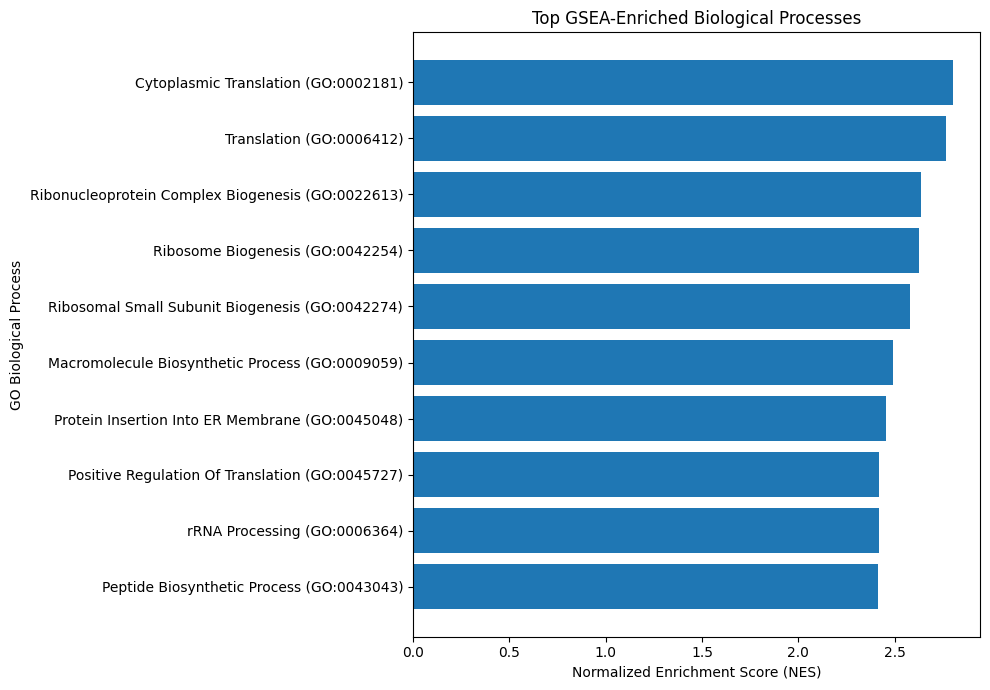

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Significant GSEA results
gsea_sig = gsea_go.res2d[
    gsea_go.res2d["FDR q-val"] < 0.05
].copy()

# Top 10 positive NES
top_positive = (
    gsea_sig[gsea_sig["NES"] > 0]
    .sort_values("NES", ascending=False)
    .head(10)
)

# Plot
plt.figure(figsize=(10, 7))

plt.barh(
    top_positive["Term"][::-1],
    top_positive["NES"][::-1]
)

plt.xlabel("Normalized Enrichment Score (NES)")
plt.ylabel("GO Biological Process")
plt.title("Top GSEA-Enriched Biological Processes")
plt.tight_layout()

plt.show()

**Visualization 1 — GSEA bar plot**


NAFLD-associated transcriptional changes are strongly enriched for processes involving translation, ribosome biogenesis, RNA processing and protein synthesis.

That is a biological interpretation of the gene-set level signal, not a claim that NAFLD directly causes those processes.

B. Negative pathways

We'll visualize the strongest Control-associated signals separately.

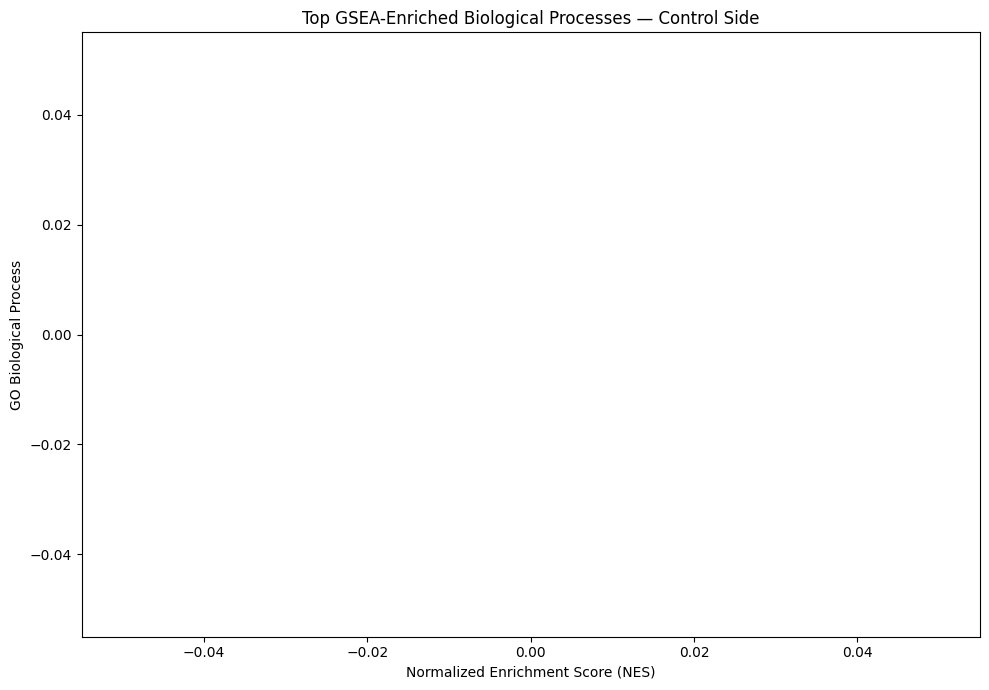

In [ ]:
# Top 10 significant negative NES pathways
top_negative = (
    gsea_sig[gsea_sig["NES"] < 0]
    .sort_values("NES", ascending=True)
    .head(10)
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_negative["Term"][::-1],
    top_negative["NES"][::-1]
)

plt.xlabel("Normalized Enrichment Score (NES)")
plt.ylabel("GO Biological Process")
plt.title("Top GSEA-Enriched Biological Processes — Control Side")
plt.tight_layout()

plt.show()

The GSEA analysis found strong and statistically significant enrichment on the positive/NAFLD side, but no negatively enriched GO biological process survived FDR correction.

These pathways showed negative enrichment trends but did not survive multiple-testing correction.

Plotting the top negative GSEA pathway

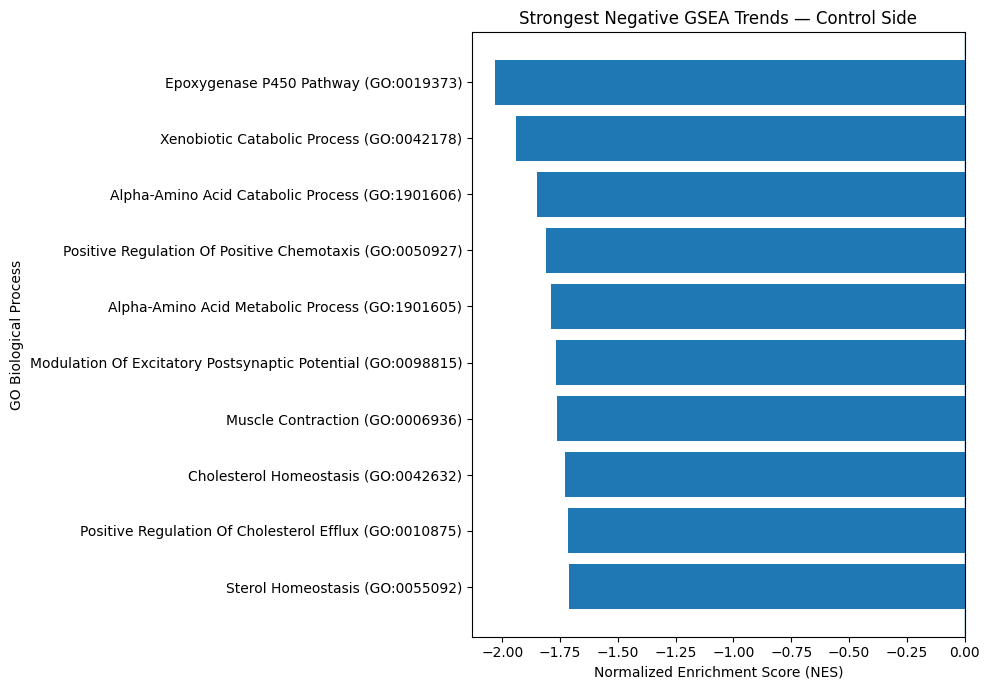

In [ ]:
import matplotlib.pyplot as plt

top_negative_all = (
    gsea_go.res2d[gsea_go.res2d["NES"] < 0]
    .sort_values("NES", ascending=True)
    .head(10)
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_negative_all["Term"][::-1],
    top_negative_all["NES"][::-1]
)

plt.axvline(0, linewidth=1)

plt.xlabel("Normalized Enrichment Score (NES)")
plt.ylabel("GO Biological Process")
plt.title("Strongest Negative GSEA Trends — Control Side")

plt.tight_layout()
plt.show()

**Visualization 2 — Individual GSEA enrichment plots**

A. Cytoplasmic Translation

NES = 2.80

This is your strongest positive signal.

B. Ribosome Biogenesis

NES = 2.63

This represents the broader ribosomal machinery.

C. Protein Insertion Into ER Membrane

NES = 2.45

For cytoplasmic translation

In [ ]:
term = "Cytoplasmic Translation (GO:0002181)"

print(gsea_go.results[term].keys())

dict_keys(['name', 'es', 'nes', 'pval', 'fdr', 'fwerp', 'tag %', 'gene %', 'lead_genes', 'matched_genes', 'hits', 'RES', 'log2err'])


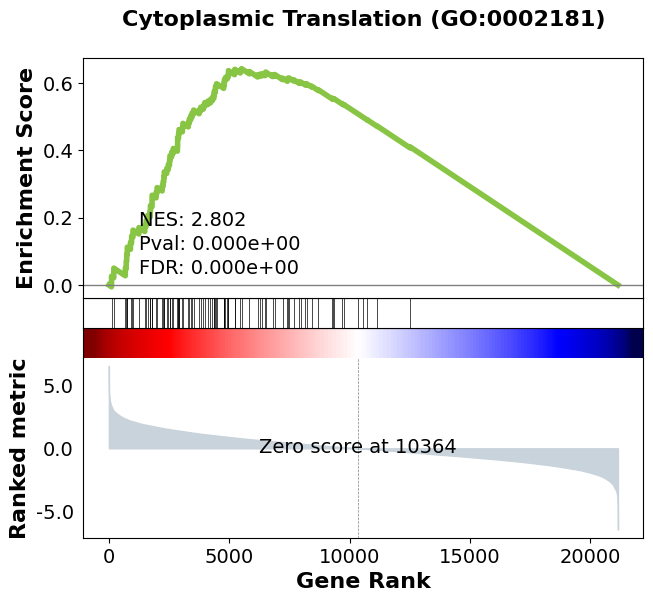

In [ ]:
from gseapy.plot import gseaplot
import matplotlib.pyplot as plt

term = "Cytoplasmic Translation (GO:0002181)"
result = gsea_go.results[term]

gseaplot(
    term=term,
    hits=result["hits"],
    nes=result["nes"],
    pval=result["pval"],
    fdr=result["fdr"],
    RES=result["RES"],
    rank_metric=gsea_go.ranking,
    figsize=(7, 6)
)

plt.show()

The GSEA bar plot explains that:

Cytoplasmic Translation is strongly enriched toward the NAFLD-associated end of the ranked gene list.

The enrichment plot lets us see how that enrichment happens across all 21,141 genes.

The three layers:

1. Ranked gene list

Your genes are ordered from strongest positive statistic → strongest negative statistic.

2. Gene hits

The vertical marks show where genes belonging to Cytoplasmic Translation occur in that ranking.

If many of those marks cluster toward the positive/NAFLD end, that supports enrichment.

3. Running enrichment score

The curve rises when we encounter genes belonging to the pathway and falls when you encounter genes that aren't part of it.

A strong peak means the pathway's genes are concentrated toward one end of the ranked list.

For the Ribosome Biogenesis

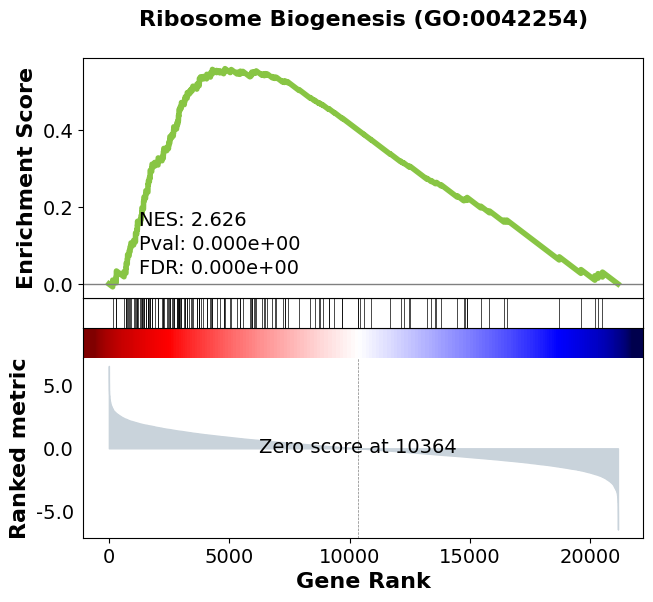

In [ ]:
from gseapy.plot import gseaplot
import matplotlib.pyplot as plt

term1 = "Ribosome Biogenesis (GO:0042254)"
result = gsea_go.results[term1]

gseaplot(
    term=term1,
    hits=result["hits"],
    nes=result["nes"],
    pval=result["pval"],
    fdr=result["fdr"],
    RES=result["RES"],
    rank_metric=gsea_go.ranking,
    figsize=(7, 6)
)

plt.show()

Ribosome Biogenesis

The results:

NES = 2.63
FDR = 0.0 as reported by GSEApy
Strong positive enrichment

Ribosomes are the cellular machinery that translates mRNA into proteins. Ribosome biogenesis is the process by which cells produce and process ribosomal RNA,
assemble ribosomal components,
build mature ribosomes,
prepare the translational machinery for protein synthesis.

So the GSEA result indicates that genes involved in this machinery are collectively shifted toward the NAFLD-associated end of your ranked gene list.

And it's relationship with the strongest pathway:

Ribosome biogenesis → more ribosomal machinery → translation

Which is biologically coherent with your other major finding,

Cytoplasmic Translation — NES ≈ 2.80

For Protein Insertion into ER Membrane

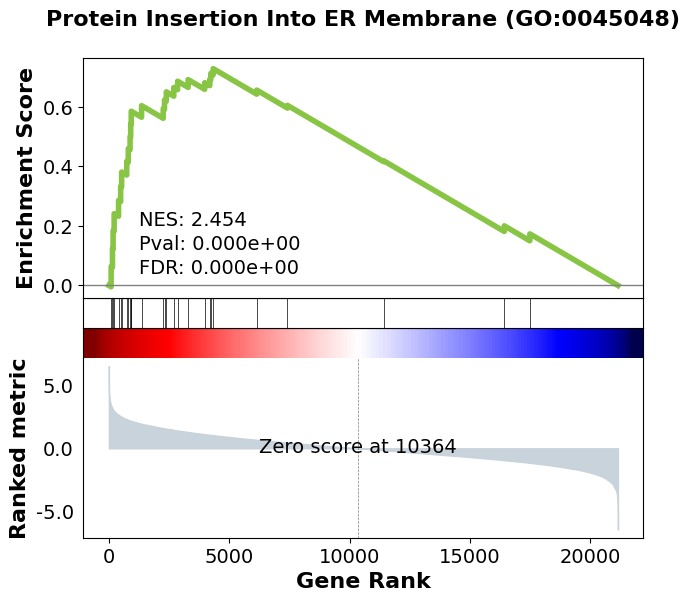

In [ ]:
from gseapy.plot import gseaplot
import matplotlib.pyplot as plt

term2 = "Protein Insertion Into ER Membrane (GO:0045048)"
result = gsea_go.results[term2]

gseaplot(
    term=term2,
    hits=result["hits"],
    nes=result["nes"],
    pval=result["pval"],
    fdr=result["fdr"],
    RES=result["RES"],
    rank_metric=gsea_go.ranking,
    figsize=(7, 6)
)

plt.show()

Protein Insertion Into ER Membrane

The result was:

NES = 2.45
FDR = 0.0 as reported
Strong positive enrichment

The endoplasmic reticulum (ER) is a major site of protein processing and trafficking.

So many proteins that are destined for cellular membranes, secretion,
organelles, and are synthesized and inserted into or transported through the ER.

So enrichment of genes involved in protein insertion into the ER membrane suggests that the NAFLD-associated transcriptome contains coordinated changes in machinery involved in protein handling and membrane-associated protein processing.

The GSEA results are pointing toward a broader biological theme which is,

altered protein synthesis and protein-processing machinery in NAFLD liver tissue.

Final interpretation:


Theme 1 — Protein synthesis / translation

Strongly enriched toward NAFLD:

Translation → ribosome → rRNA processing → protein biosynthesis


Theme 2 — Protein trafficking / ER

Protein insertion into ER membrane and related membrane/protein-localization processes.


Theme 3 — Mitochondrial protein handling

Establishment of protein localization to mitochondria

This could be particularly interesting in a metabolic disease context.

Theme 4 — Membrane organization

You also have membrane fission, membrane organization and multivesicular body organization

**Save the three representative GSEA curves as SVG**

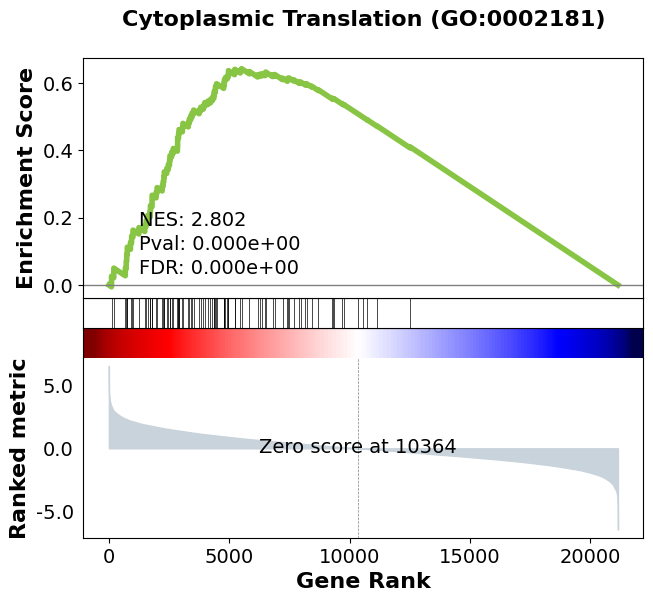

In [ ]:
result = gsea_go.results[term]

axes = gseaplot(
    term=term,
    hits=result["hits"],
    nes=result["nes"],
    pval=result["pval"],
    fdr=result["fdr"],
    RES=result["RES"],
    rank_metric=gsea_go.ranking,
    figsize=(7, 6)
)

fig = axes[0].figure

fig.savefig(
    "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/Svgs/GSEA_Cytoplasmic_Translation.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

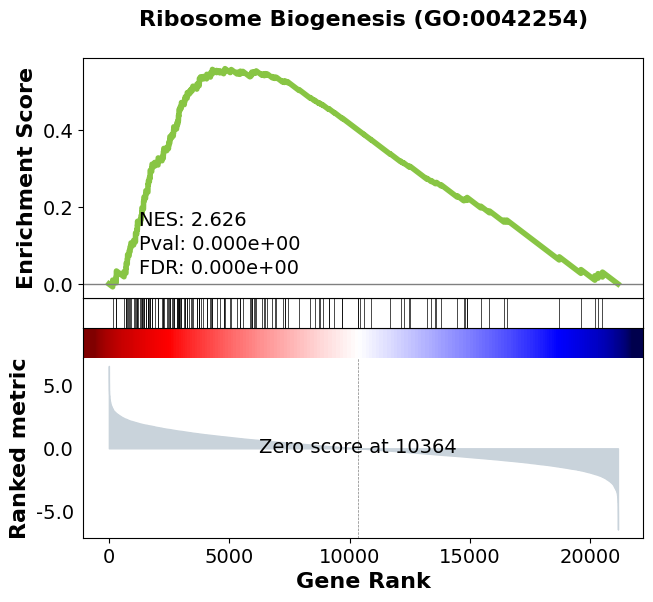

In [ ]:
result1 = gsea_go.results[term1]

axes = gseaplot(
    term=term1,
    hits=result1["hits"],
    nes=result1["nes"],
    pval=result1["pval"],
    fdr=result1["fdr"],
    RES=result1["RES"],
    rank_metric=gsea_go.ranking,
    figsize=(7, 6)
)

fig = axes[0].figure

fig.savefig(
    "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/Svgs/GSEA_Ribosome_Biogenesis.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

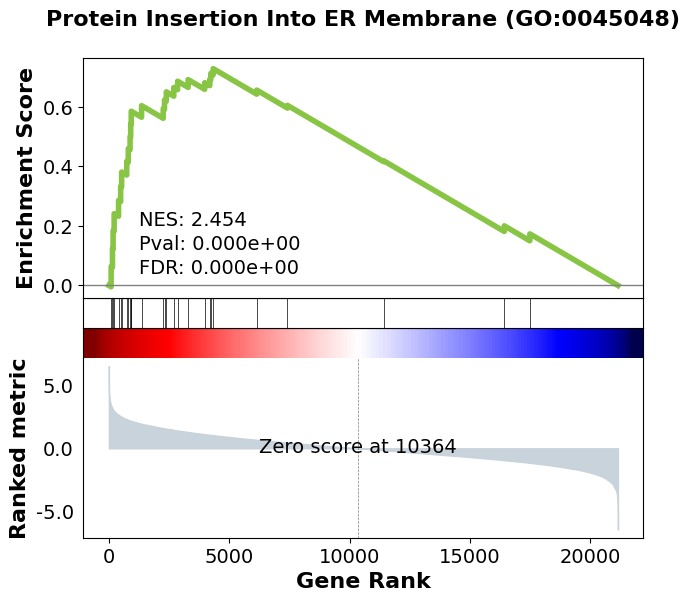

In [ ]:
result2 = gsea_go.results[term2]

axes = gseaplot(
    term=term2,
    hits=result2["hits"],
    nes=result2["nes"],
    pval=result2["pval"],
    fdr=result2["fdr"],
    RES=result2["RES"],
    rank_metric=gsea_go.ranking,
    figsize=(7, 6)
)

fig = axes[0].figure

fig.savefig(
    "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/Svgs/GSEA_Protein_Insertion_ER_Membrane.svg",
    format="svg",
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

**Create the major findings table**

In [ ]:
import pandas as pd

major_findings = pd.DataFrame({
    "Analysis": [
        "Differential Expression",
        "GO Over-Representation Analysis",
        "KEGG Over-Representation Analysis",
        "GO GSEA",
        "Strongest positive GSEA",
        "Second major GSEA theme",
        "Third major GSEA theme",
        "Negative GSEA"
    ],

    "Finding": [
        "64 significant DEGs: 31 upregulated and 33 downregulated",
        "No GO Biological Process terms significant at FDR < 0.05",
        "No KEGG pathways significant at FDR < 0.05",
        "494 GO Biological Process terms significant at FDR < 0.05",
        "Cytoplasmic Translation",
        "Ribosome Biogenesis",
        "Protein Insertion Into ER Membrane",
        "No negative GO terms significant at FDR < 0.05"
    ],

    "Statistic": [
        "64 DEGs",
        "0 significant terms",
        "0 significant pathways",
        "494 significant terms",
        "NES = 2.80",
        "NES = 2.63",
        "NES = 2.45",
        "Strongest: Epoxygenase P450 Pathway, NES = -2.03"
    ],

    "Interpretation": [
        "A relatively small set of individual genes showed significant differential expression.",
        "The 64 DEGs were not sufficiently concentrated into GO categories for significant ORA.",
        "The DEG list did not produce FDR-significant KEGG enrichment.",
        "Using the complete ranked transcriptome revealed coordinated biological changes that ORA did not detect.",
        "Strong enrichment of genes involved in protein synthesis and translation.",
        "Enrichment of genes involved in ribosome production and maturation.",
        "Enrichment of genes involved in ER membrane protein insertion and processing.",
        "Control-side metabolic trends were observed but did not survive multiple-testing correction."
    ]
})

major_findings

,Analysis,Finding,Statistic,Interpretation
0,Differential Expression,64 significant DEGs: 31 upregulated and 33 dow...,64 DEGs,A relatively small set of individual genes sho...
1,GO Over-Representation Analysis,No GO Biological Process terms significant at ...,0 significant terms,The 64 DEGs were not sufficiently concentrated...
2,KEGG Over-Representation Analysis,No KEGG pathways significant at FDR < 0.05,0 significant pathways,The DEG list did not produce FDR-significant K...
3,GO GSEA,494 GO Biological Process terms significant at...,494 significant terms,Using the complete ranked transcriptome reveal...
4,Strongest positive GSEA,Cytoplasmic Translation,NES = 2.80,Strong enrichment of genes involved in protein...
5,Second major GSEA theme,Ribosome Biogenesis,NES = 2.63,Enrichment of genes involved in ribosome produ...
6,Third major GSEA theme,Protein Insertion Into ER Membrane,NES = 2.45,Enrichment of genes involved in ER membrane pr...
7,Negative GSEA,No negative GO terms significant at FDR < 0.05,"Strongest: Epoxygenase P450 Pathway, NES = -2.03",Control-side metabolic trends were observed bu...


Saving the major findings

In [ ]:
major_findings.to_csv(
    "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/results/Major_Findings.csv",
    index=False
)

print("Saved:",
      "/content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/results/Major_Findings.csv")

Saved: /content/drive/MyDrive/NAFLD_transcriptomics(GSE260666)/results/Major_Findings.csv


The Summary:

1. Differential expression

You have:

MA plot
Volcano plot
64 significant DEGs
31 upregulated
33 downregulated

These establish which genes changed.

2. DEG-level biological visualization

You have:

Top-20 DEG heatmap
Group annotation heatmap

These show how the expression patterns separate NAFLD and controls.

3. Functional enrichment

Your ORA showed:

GO up: no FDR-significant terms
GO down: no FDR-significant terms
KEGG up: no FDR-significant terms
KEGG down: no FDR-significant term

4. GSEA

This is where the strongest biological story appears.

You have 494 FDR-significant GO terms, with the strongest positive terms heavily concentrated around:

Cytoplasmic translation
Translation
Ribonucleoprotein complex biogenesis
Ribosome biogenesis
Ribosomal subunit biogenesis
Protein insertion into ER membrane
Translational initiation
rRNA processing
Mitochondrial protein localization
Membrane organization

### Differential expression and pathway analysis

Differential expression analysis identified 64 significantly differentially expressed genes between NAFLD and control samples, comprising 31 upregulated and 33 downregulated genes. Although individual genes showed statistically significant differences, over-representation analysis of the significant gene list did not identify any Gene Ontology Biological Process or KEGG pathways that remained significant after multiple-testing correction (FDR < 0.05).

To assess whether coordinated biological changes were present beyond the relatively small set of significant DEGs, preranked Gene Set Enrichment Analysis (GSEA) was performed using the complete ranked transcriptome of 21,141 genes. In contrast to the DEG-based enrichment analyses, GSEA identified 494 GO Biological Process terms at FDR < 0.05.

The strongest positive enrichment was observed for **Cytoplasmic Translation** (NES = 2.80), indicating coordinated enrichment of translation-associated genes toward the NAFLD-associated end of the ranked transcriptome. **Ribosome Biogenesis** was also strongly enriched (NES = 2.63), consistent with a broader alteration in the machinery responsible for ribosome production and maturation. A further significant enrichment was observed for **Protein Insertion Into ER Membrane** (NES = 2.45), suggesting coordinated changes in genes involved in the handling and insertion of newly synthesized proteins into the endoplasmic reticulum membrane.

Together, these findings point to a coherent transcriptomic pattern involving protein synthesis, ribosomal machinery, and protein-processing pathways in the NAFLD samples. Importantly, these results demonstrate why pathway analysis based only on statistically significant DEGs can miss broader biological signals: although the DEG-based GO and KEGG analyses were not significant after FDR correction, GSEA detected coordinated shifts across the ranked transcriptome.

Several pathways showed negative enrichment, including xenobiotic/P450 metabolism, cholesterol homeostasis, and fatty-acid metabolism. However, none of the negative GO terms reached FDR < 0.05. These findings should therefore be regarded as exploratory trends rather than statistically significant pathway alterations.

Overall, the transcriptomic analysis identified a relatively modest number of individual DEGs but a broader coordinated enrichment of biological processes related to translation, ribosome biogenesis, and ER-associated protein processing in NAFLD liver tissue.

**THE END**